# Obligatorio de Machine Learning: cancelación de reservas

**Objetivo:** preparar y auditar el dataset para predecir `is_canceled`.

Esta primera etapa presenta resultados reales del archivo recibido. No elimina columnas o filas, no imputa valores y no entrena modelos.

## 1. Requisitos y alcance identificado

### Requisitos obligatorios de esta etapa

1. Mantener una estructura de proyecto reproducible.
2. Preparar un notebook ejecutable desde cero en Google Colab.
3. Cargar el CSV y verificar dimensiones, tipos, nulos, duplicados y distribución de `is_canceled`.
4. Auditar posibles fugas de información, especialmente `reservation_status` y `reservation_status_date`.
5. Proponer partición y validación sin entrenar modelos.
6. Mostrar resultados reales y justificar las decisiones.

### Qué aporta el PDF adjunto

El PDF es el artículo técnico *Hotel booking demand datasets* (Antonio, Almeida y Nunes, 2019), no una rúbrica universitaria. Documenta dos hoteles de Portugal, reservas con llegada entre julio de 2015 y agosto de 2017 y el objetivo de cancelación. También advierte que la fecha del objetivo debe ser posterior a las variables de entrada para evitar fuga de información.

La fuente indica que valores `NULL` en variables categóricas como `agent` y `company` pueden significar *no aplica*. Por eso se reportan tal como los interpreta `pandas`, pero no se imputan ni se decide todavía su tratamiento semántico.

## 2. Entorno y carga reproducible

In [1]:
from pathlib import Path
from io import StringIO
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 100)

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")

Python: 3.13.5
pandas: 2.2.3
numpy: 2.1.3


In [2]:
candidates = [
    Path("data/hotel_bookings.csv"),
    Path("../data/hotel_bookings.csv"),
    Path("/content/hotel_bookings.csv"),
]
data_path = next((path for path in candidates if path.exists()), None)

if data_path is None:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "No se encontró data/hotel_bookings.csv. "
            "Ejecutá el notebook desde la raíz del proyecto o copiá el archivo."
        ) from exc
    print("Seleccioná hotel_bookings.csv en el diálogo de Colab.")
    uploaded = files.upload()
    if "hotel_bookings.csv" not in uploaded:
        raise FileNotFoundError("Se debe subir un archivo llamado hotel_bookings.csv")
    data_path = Path("hotel_bookings.csv")

df = pd.read_csv(data_path)
print(f"Archivo cargado: {data_path}")
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Archivo cargado: ..\data\hotel_bookings.csv
Dimensiones: 119,390 filas x 32 columnas


In [3]:
display(df.head())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 3. Auditoría inicial de calidad

In [4]:
buffer = StringIO()
df.info(buf=buffer)
print(buffer.getvalue())

type_summary = (
    df.dtypes.astype(str)
    .rename("dtype")
    .to_frame()
    .assign(unique_values=df.nunique(dropna=True))
)
display(type_summary)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

,dtype,unique_values
hotel,object,2
is_canceled,int64,2
lead_time,int64,479
arrival_date_year,int64,3
arrival_date_month,object,12
arrival_date_week_number,int64,53
arrival_date_day_of_month,int64,31
stays_in_weekend_nights,int64,17
stays_in_week_nights,int64,35
adults,int64,14


In [5]:
missing = (
    df.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_pct=lambda x: 100 * x["missing_count"] / len(df))
    .query("missing_count > 0")
    .sort_values("missing_count", ascending=False)
)
display(missing)

raw_nullable = pd.read_csv(
    data_path,
    usecols=["children", "country", "agent", "company"],
    keep_default_na=False,
    dtype=str,
)
sentinels = []
for column in raw_nullable.columns:
    for token in ["", "NA", "NULL"]:
        count = int((raw_nullable[column].astype(str) == token).sum())
        if count:
            sentinels.append({"column": column, "raw_token": token or "<empty>", "count": count})
display(pd.DataFrame(sentinels))
print("No se imputó ningún valor. La tabla distingue el resultado de pandas del token crudo del CSV.")

,missing_count,missing_pct
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


,column,raw_token,count
0,children,NA,4
1,country,NULL,488
2,agent,NULL,16340
3,company,NULL,112593


No se imputó ningún valor. La tabla distingue el resultado de pandas del token crudo del CSV.


In [6]:
duplicate_count = int(df.duplicated().sum())
print(f"Filas duplicadas exactas, contando desde la segunda aparición: {duplicate_count:,}")
print(f"Filas únicas exactas: {len(df.drop_duplicates()):,}")
print("No se eliminaron duplicados: su definición y tratamiento requieren una decisión metodológica posterior.")

Filas duplicadas exactas, contando desde la segunda aparición: 31,994


Filas únicas exactas: 87,396
No se eliminaron duplicados: su definición y tratamiento requieren una decisión metodológica posterior.


## 4. Distribución del objetivo en el desarrollo definitivo

La distribución del objetivo y toda relación usada para desarrollar modelos se calculan sobre `creation_final_train_index`. El dataset completo se conserva únicamente para descripciones estructurales que no consultan el resultado del test.


,count,percentage
is_canceled,,
0,44944,63.850886
1,25445,36.149114


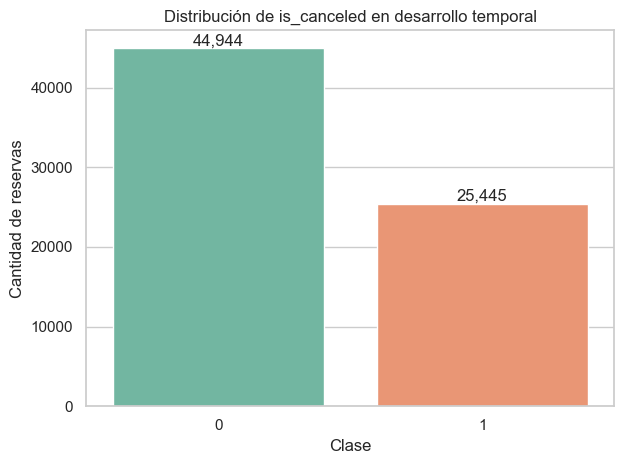

In [7]:
month_number = {
    month: number
    for number, month in enumerate(
        ["January", "February", "March", "April", "May", "June",
         "July", "August", "September", "October", "November", "December"],
        start=1,
    )
}
arrival_date = pd.to_datetime({
    "year": df["arrival_date_year"],
    "month": df["arrival_date_month"].map(month_number),
    "day": df["arrival_date_day_of_month"],
})
booking_creation_date_proxy = arrival_date - pd.to_timedelta(df["lead_time"], unit="D")

CREATION_TEST_START = pd.Timestamp("2016-11-01")
CREATION_TEST_END = pd.Timestamp("2016-12-31")
CREATION_CENSOR_BUFFER_START = pd.Timestamp("2017-01-01")

creation_final_train_mask = (
    (booking_creation_date_proxy < CREATION_TEST_START)
    & (arrival_date < CREATION_TEST_START)
)
creation_purged_before_test_mask = (
    (booking_creation_date_proxy < CREATION_TEST_START)
    & (arrival_date >= CREATION_TEST_START)
)
creation_final_test_mask = booking_creation_date_proxy.between(
    CREATION_TEST_START, CREATION_TEST_END
)
creation_censor_buffer_mask = booking_creation_date_proxy >= CREATION_CENSOR_BUFFER_START

creation_final_train_index = df.index[creation_final_train_mask].to_numpy()
creation_purged_before_test_index = df.index[creation_purged_before_test_mask].to_numpy()
creation_final_test_index = df.index[creation_final_test_mask].to_numpy()
creation_censor_buffer_index = df.index[creation_censor_buffer_mask].to_numpy()

EARLY_CREATION_FINAL_TRAIN_INDEX = creation_final_train_index.copy()
EARLY_CREATION_FINAL_TEST_INDEX = creation_final_test_index.copy()

assert len(creation_final_train_index) == 70_389
assert len(creation_final_test_index) == 10_196
assert set(creation_final_train_index).isdisjoint(creation_final_test_index)

development_df = df.loc[creation_final_train_index]
target_distribution = pd.DataFrame({
    "count": development_df["is_canceled"].value_counts().sort_index(),
    "percentage": 100 * development_df["is_canceled"].value_counts(normalize=True).sort_index(),
})
display(target_distribution)

ax = sns.countplot(
    data=development_df, x="is_canceled", hue="is_canceled",
    legend=False, palette="Set2",
)
ax.set(
    title="Distribución de is_canceled en desarrollo temporal",
    xlabel="Clase", ylabel="Cantidad de reservas",
)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")
plt.tight_layout()
plt.show()


## 5. Auditoría de fuga de información

La relación con el objetivo se verifica exclusivamente en desarrollo. El test definitivo no se consulta para esta auditoría.


In [8]:
status_vs_target = pd.crosstab(
    development_df["reservation_status"],
    development_df["is_canceled"],
    margins=True,
)
display(status_vs_target)

status_date = pd.to_datetime(
    development_df["reservation_status_date"], errors="raise"
)
print(
    "Rango de reservation_status_date en desarrollo:",
    status_date.min().date(), "a", status_date.max().date(),
)


is_canceled,0,1,All
reservation_status,,,
Canceled,0,24658,24658
Check-Out,44944,0,44944
No-Show,0,787,787
All,44944,25445,70389


Rango de reservation_status_date en desarrollo: 2014-10-17 a 2016-11-21


### Decisión sobre fuga

- **`reservation_status`: fuga directa.** `Check-Out` coincide sólo con `is_canceled=0`; `Canceled` y `No-Show` coinciden sólo con `is_canceled=1`. La variable revela el resultado.
- **`reservation_status_date`: fuga temporal.** Es la fecha en la que se fijó el último estado. Puede conocerse después de la cancelación, el no-show o el check-out. No representa información disponible al emitir una predicción previa al resultado.
- **Variables que requieren confirmar el instante de predicción:** `assigned_room_type`, `booking_changes`, `country`, `deposit_type` y `days_in_waiting_list`. El artículo indica que algunos valores pueden cambiar hasta el check-in/cancelación o conocerse durante la operación. No se declaran automáticamente como fuga, pero deberán incluirse sólo si estaban disponibles en el momento exacto definido para predecir.

Las columnas permanecen en `df` para conservar el dataset original. En una etapa de modelado se construiría una lista explícita de predictores excluyendo las variables no disponibles, con la justificación documentada.

## 6. Estrategia temporal definitiva y auditoría de exposición

Esta sección reemplaza retrospectivamente la partición inicial por llegada. La estrategia canónica se define por fecha aproximada de creación y disponibilidad conservadora de la etiqueta.


In [9]:
outer_creation_split_early = pd.DataFrame([
    {
        "bloque": "Desarrollo elegible antes del test",
        "filas": len(creation_final_train_index),
        "uso": "EDA predictivo, folds y futuro ajuste final",
    },
    {
        "bloque": "Purga previa al test",
        "filas": len(creation_purged_before_test_index),
        "uso": "Excluir: etiqueta no disponible al inicio del test",
    },
    {
        "bloque": "Test final por creación (nov-dic 2016)",
        "filas": len(creation_final_test_index),
        "uso": "Evaluación final única; no consultar el objetivo",
    },
    {
        "bloque": "Colchón de censura (creaciones 2017)",
        "filas": len(creation_censor_buffer_index),
        "uso": "Excluir por seguimiento potencialmente incompleto",
    },
])
display(outer_creation_split_early)
print("Rango de llegadas:", arrival_date.min().date(), "a", arrival_date.max().date())


,bloque,filas,uso
0,Desarrollo elegible antes del test,70389,"EDA predictivo, folds y futuro ajuste final"
1,Purga previa al test,12240,Excluir: etiqueta no disponible al inicio del ...
2,Test final por creación (nov-dic 2016),10196,Evaluación final única; no consultar el objetivo
3,Colchón de censura (creaciones 2017),26565,Excluir por seguimiento potencialmente incompleto


Rango de llegadas: 2015-07-01 a 2017-08-31


In [10]:
legacy_arrival_eda_mask = arrival_date <= pd.Timestamp("2016-12-31")
legacy_arrival_eda_index = set(df.index[legacy_arrival_eda_mask])
final_test_index_set = set(creation_final_test_index)
legacy_test_exposure_index = legacy_arrival_eda_index.intersection(final_test_index_set)

exposure_audit = pd.DataFrame([
    {
        "métrica": "Reservas del EDA anterior por llegada",
        "filas": int(legacy_arrival_eda_mask.sum()),
    },
    {
        "métrica": "Reservas del test definitivo incluidas en ese EDA",
        "filas": len(legacy_test_exposure_index),
    },
    {
        "métrica": "Reservas del desarrollo definitivo para EDA corregido",
        "filas": len(creation_final_train_index),
    },
])
display(exposure_audit)

assert int(legacy_arrival_eda_mask.sum()) == 78_703
assert len(legacy_test_exposure_index) == 2_923
assert set(creation_final_train_index).isdisjoint(final_test_index_set)
print("Exposición histórica identificada; el objetivo del test no se consulta aquí.")


,métrica,filas
0,Reservas del EDA anterior por llegada,78703
1,Reservas del test definitivo incluidas en ese EDA,2923
2,Reservas del desarrollo definitivo para EDA co...,70389


Exposición histórica identificada; el objetivo del test no se consulta aquí.


### Justificación y alcance de la corrección

El objetivo operativo es predecir al registrar la reserva. Por eso, la separación canónica usa `arrival_date - lead_time` como proxy de creación. El desarrollo elegible contiene reservas creadas antes del 01/11/2016 cuya llegada —aproximación conservadora de disponibilidad de la etiqueta— también es anterior a esa fecha. El test mantiene las creaciones de noviembre–diciembre de 2016; no se cambia para evitar escoger un nuevo test después de observar el problema.

**Transparencia sobre la exposición.** El EDA original utilizó 78.703 reservas seleccionadas por llegada. Al adoptar después el test por creación, se comprobó que 2.923 de sus 10.196 reservas ya habían aparecido en gráficos y resúmenes anteriores, algunos basados en `is_canceled`. Por lo tanto, no puede afirmarse que el test estuvo completamente aislado desde el inicio. Esta exposición no equivale a entrenamiento ni ajuste de hiperparámetros, pero puede haber influido indirectamente en decisiones exploratorias. Las celdas afectadas se recalculan ahora con las 70.389 reservas de desarrollo y la limitación deberá informarse en la evaluación final.

Las seis ventanas expansivas y la purga de etiquetas se formalizan en la Etapa 3. La fecha de creación sigue siendo aproximada y algunas variables pueden reflejar actualizaciones posteriores.


## 7. Conclusiones de la etapa

- El archivo completo contiene 119.390 reservas y 32 columnas; esta es información descriptiva estructural.
- La distribución de `is_canceled` y la auditoría de variables con posible fuga se calculan sobre las 70.389 reservas del desarrollo definitivo.
- `reservation_status` y `reservation_status_date` no deben entrar como predictores.
- Hay 31.994 filas duplicadas exactas contando desde la segunda aparición en el dataset completo. Su relación con el objetivo se analiza sólo dentro de desarrollo.
- La estrategia definitiva reserva 10.196 creaciones de noviembre–diciembre de 2016 para test y excluye los bloques purgados o censurados.
- El test tuvo exposición exploratoria histórica en 2.923 filas; no fue usado por los modelos, pero no puede considerarse aislado desde el comienzo.


# Etapa 2 - Análisis Exploratorio de Datos (EDA)

Esta etapa separa dos usos de los datos:

- Las descripciones estructurales que no dependen del objetivo —tamaño, columnas y conteo general de duplicados— pueden referirse al dataset completo.
- Todos los gráficos, asociaciones y decisiones que consultan `is_canceled` se calculan exclusivamente sobre `creation_final_train_index`, el desarrollo temporal definitivo de 70.389 reservas.

El EDA original por llegada incluyó accidentalmente 2.923 filas del test definitivo. Las salidas siguientes fueron recalculadas y sustituyen esas cifras. `reservation_status` y `reservation_status_date` continúan excluidas por fuga.


In [11]:
# Vista no destructiva del desarrollo temporal definitivo.
eda_train = df.loc[creation_final_train_index].copy()
eda_train_mask = df.index.isin(creation_final_train_index)

leakage_columns = ["reservation_status", "reservation_status_date"]
assert all(column in df.columns for column in leakage_columns)
assert len(eda_train) == 70_389
assert set(eda_train.index).isdisjoint(creation_final_test_index)

print(f"Reservas disponibles para el EDA predictivo corregido: {len(eda_train):,}")
print(
    "Creación aproximada:",
    booking_creation_date_proxy.loc[eda_train.index].min().date(), "a",
    booking_creation_date_proxy.loc[eda_train.index].max().date(),
)
print("Filas compartidas con el test definitivo: 0")
print("Columnas que no se usarán como predictores:", leakage_columns)


Reservas disponibles para el EDA predictivo corregido: 70,389
Creación aproximada: 2013-06-24 a 2016-10-31
Filas compartidas con el test definitivo: 0
Columnas que no se usarán como predictores: ['reservation_status', 'reservation_status_date']


## 2.1 Distribución de cancelaciones

El primer gráfico cuantifica el balance de la variable objetivo dentro de entrenamiento. Se muestran simultáneamente cantidades y porcentajes para dimensionar el problema.


,estado,reservas,porcentaje
0,No cancelada,44944,63.85
1,Cancelada,25445,36.15


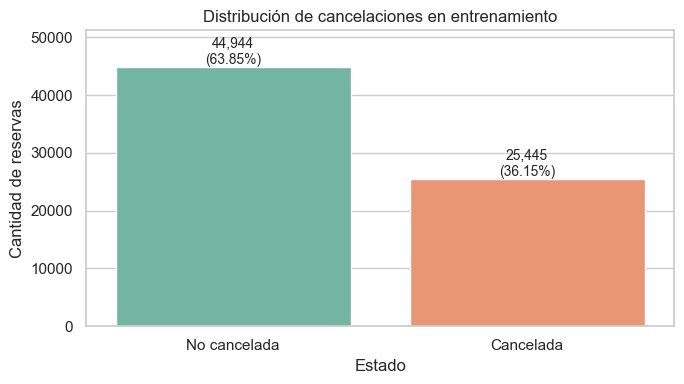

In [12]:
cancel_labels = {0: "No cancelada", 1: "Cancelada"}
cancel_summary = (
    eda_train["is_canceled"]
    .value_counts()
    .sort_index()
    .rename_axis("is_canceled")
    .reset_index(name="reservas")
)
cancel_summary["estado"] = cancel_summary["is_canceled"].map(cancel_labels)
cancel_summary["porcentaje"] = 100 * cancel_summary["reservas"] / len(eda_train)
display(cancel_summary[["estado", "reservas", "porcentaje"]].round({"porcentaje": 2}))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=cancel_summary, x="estado", y="reservas", hue="estado", legend=False, palette="Set2", ax=ax)
for patch, row in zip(ax.patches, cancel_summary.itertuples()):
    ax.annotate(
        f"{row.reservas:,.0f}\n({row.porcentaje:.2f}%)",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center", va="bottom", fontsize=10,
    )
ax.set(title="Distribución de cancelaciones en entrenamiento", xlabel="Estado", ylabel="Cantidad de reservas")
ax.set_ylim(0, cancel_summary["reservas"].max() * 1.14)
plt.tight_layout()
plt.show()


**Conclusión recalculada.** En el desarrollo temporal definitivo hay 44.944 reservas no canceladas (63,85%) y 25.445 canceladas (36,15%). La clase cancelada sigue siendo minoritaria, pero conserva representación suficiente. El cambio respecto al EDA anterior es pequeño y no altera la decisión de usar métricas sensibles a ambas clases en vez de accuracy.


## 2.2 Comparación entre hoteles

Se comparan tamaños y tasas de cancelación. La tasa permite una comparación justa aunque los hoteles tengan distintas cantidades de reservas.


,hotel,reservas,canceladas,tasa_cancelacion_pct
0,City Hotel,46222,18979,41.06
1,Resort Hotel,24167,6466,26.76


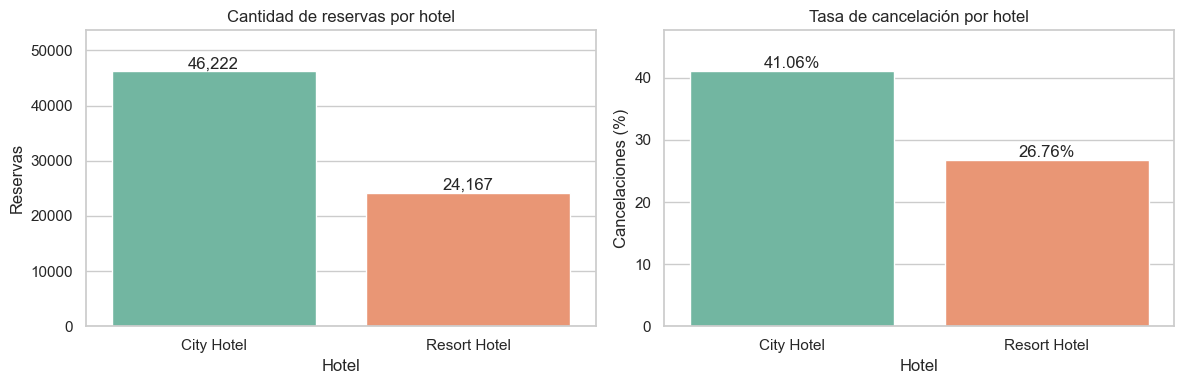

In [13]:
hotel_summary = (
    eda_train.groupby("hotel")["is_canceled"]
    .agg(reservas="size", canceladas="sum", tasa_cancelacion="mean")
    .reset_index()
)
hotel_summary["tasa_cancelacion_pct"] = 100 * hotel_summary["tasa_cancelacion"]
display(hotel_summary[["hotel", "reservas", "canceladas", "tasa_cancelacion_pct"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=hotel_summary, x="hotel", y="reservas", hue="hotel", legend=False, palette="Set2", ax=axes[0])
sns.barplot(data=hotel_summary, x="hotel", y="tasa_cancelacion_pct", hue="hotel", legend=False, palette="Set2", ax=axes[1])
axes[0].set(title="Cantidad de reservas por hotel", xlabel="Hotel", ylabel="Reservas")
axes[1].set(title="Tasa de cancelación por hotel", xlabel="Hotel", ylabel="Cancelaciones (%)")
for ax, column, fmt in [(axes[0], "reservas", "{:,.0f}"), (axes[1], "tasa_cancelacion_pct", "{:.2f}%")]:
    for patch, value in zip(ax.patches, hotel_summary[column]):
        ax.annotate(fmt.format(value), (patch.get_x() + patch.get_width() / 2, patch.get_height()), ha="center", va="bottom")
    ax.set_ylim(0, hotel_summary[column].max() * 1.16)
plt.tight_layout()
plt.show()


**Conclusión recalculada.** City Hotel reúne 46.222 reservas y cancela el 41,06%; Resort Hotel reúne 24.167 y cancela el 26,76%. La asociación entre hotel y cancelación se mantiene en desarrollo, por lo que continúa justificado conservar `hotel` como predictor y reportar resultados por establecimiento.


## 2.3 Anticipación de las reservas (`lead_time`)

Se combinan una comparación de distribuciones sin mostrar valores extremos en el boxplot y tasas por intervalos de anticipación. La ocultación visual de extremos no altera los datos.


,intervalo,reservas,tasa_cancelacion_pct
0,0-7,12399,10.16
1,8-30,10885,26.42
2,31-90,17597,36.11
3,91-180,14741,43.09
4,181-365,13228,56.41
5,>365,1539,74.07


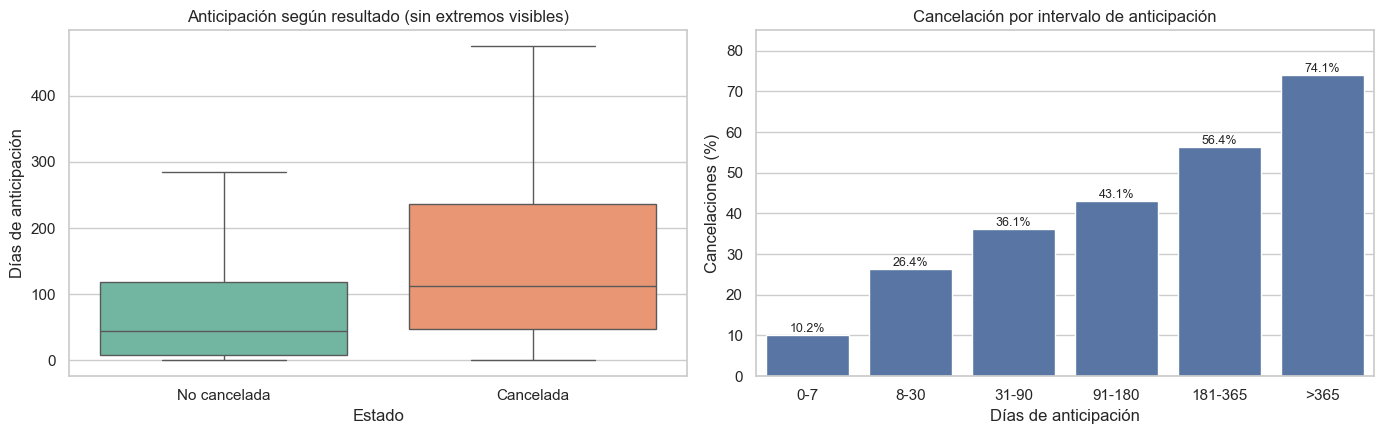

In [14]:
lead_order = ["0-7", "8-30", "31-90", "91-180", "181-365", ">365"]
lead_interval = pd.cut(
    eda_train["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, np.inf],
    labels=lead_order,
)
lead_summary = (
    eda_train.assign(intervalo=lead_interval)
    .groupby("intervalo", observed=False)["is_canceled"]
    .agg(reservas="size", tasa_cancelacion="mean")
    .reset_index()
)
lead_summary["tasa_cancelacion_pct"] = 100 * lead_summary["tasa_cancelacion"]
display(lead_summary[["intervalo", "reservas", "tasa_cancelacion_pct"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=eda_train, x="is_canceled", y="lead_time", hue="is_canceled", legend=False, showfliers=False, palette="Set2", ax=axes[0])
axes[0].set_xticks([0, 1], ["No cancelada", "Cancelada"])
axes[0].set(title="Anticipación según resultado (sin extremos visibles)", xlabel="Estado", ylabel="Días de anticipación")
sns.barplot(data=lead_summary, x="intervalo", y="tasa_cancelacion_pct", color="#4C72B0", ax=axes[1])
for patch, value in zip(axes[1].patches, lead_summary["tasa_cancelacion_pct"]):
    axes[1].annotate(f"{value:.1f}%", (patch.get_x() + patch.get_width() / 2, patch.get_height()), ha="center", va="bottom", fontsize=9)
axes[1].set(title="Cancelación por intervalo de anticipación", xlabel="Días de anticipación", ylabel="Cancelaciones (%)")
axes[1].set_ylim(0, 85)
plt.tight_layout()
plt.show()


**Conclusión recalculada.** La mediana de `lead_time` es 44 días en reservas no canceladas y 113 en canceladas. La tasa aumenta desde 10,16% para 0–7 días hasta 74,07% para más de 365 días. La asociación marcada y no lineal se mantiene sin usar el test; no implica causalidad.


## 2.4 Tipos de depósito

Se comparan las tasas y el tamaño de cada categoría para evitar interpretar porcentajes sin considerar su soporte.


,deposit_type,reservas,canceladas,tasa_cancelacion_pct
0,Non Refund,9557,9473,99.12
1,No Deposit,60699,15963,26.30
2,Refundable,133,9,6.77


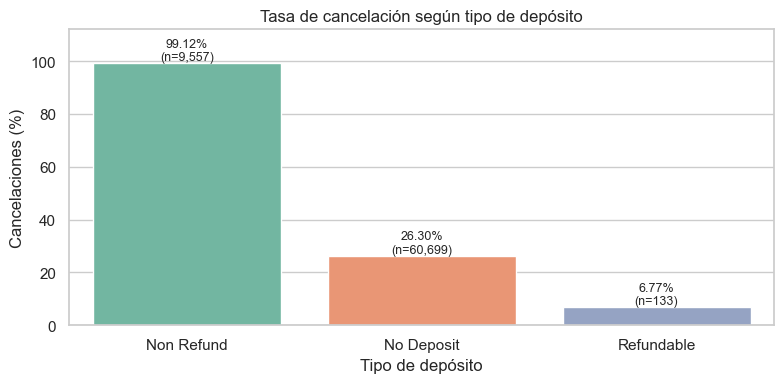

In [15]:
deposit_summary = (
    eda_train.groupby("deposit_type")["is_canceled"]
    .agg(reservas="size", canceladas="sum", tasa_cancelacion="mean")
    .sort_values("tasa_cancelacion", ascending=False)
    .reset_index()
)
deposit_summary["tasa_cancelacion_pct"] = 100 * deposit_summary["tasa_cancelacion"]
display(deposit_summary[["deposit_type", "reservas", "canceladas", "tasa_cancelacion_pct"]].round(2))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=deposit_summary, x="deposit_type", y="tasa_cancelacion_pct", hue="deposit_type", legend=False, palette="Set2", ax=ax)
for patch, row in zip(ax.patches, deposit_summary.itertuples()):
    ax.annotate(f"{row.tasa_cancelacion_pct:.2f}%\n(n={row.reservas:,})", (patch.get_x() + patch.get_width() / 2, patch.get_height()), ha="center", va="bottom", fontsize=9)
ax.set(title="Tasa de cancelación según tipo de depósito", xlabel="Tipo de depósito", ylabel="Cancelaciones (%)")
ax.set_ylim(0, 112)
plt.tight_layout()
plt.show()


**Conclusión recalculada.** `Non Refund` presenta 99,12% de cancelación (9.473 de 9.557), frente a 26,30% en `No Deposit`; `Refundable` tiene 6,77%, con sólo 133 observaciones. El patrón extremo persiste en desarrollo. No se descarta la variable, pero su disponibilidad al crear la reserva sigue siendo incierta y exige un análisis de sensibilidad.


## 2.5 Estacionalidad por mes de llegada

Los meses se ordenan cronológicamente y se grafica la tasa de cancelación dentro del desarrollo definitivo. La cobertura por mes es desigual porque se exige creación y disponibilidad aproximada de etiqueta anteriores al test; por ello estas diferencias combinan estacionalidad y composición temporal.


,mes,reservas,tasa_cancelacion_pct
0,Ene,2248,24.78
1,Feb,3891,34.36
2,Mar,4824,30.62
3,Abr,5428,37.97
4,May,5478,34.96
5,Jun,5292,39.61
6,Jul,7348,37.53
7,Ago,8952,38.24
8,Sep,10508,39.17
9,Oct,11160,38.05


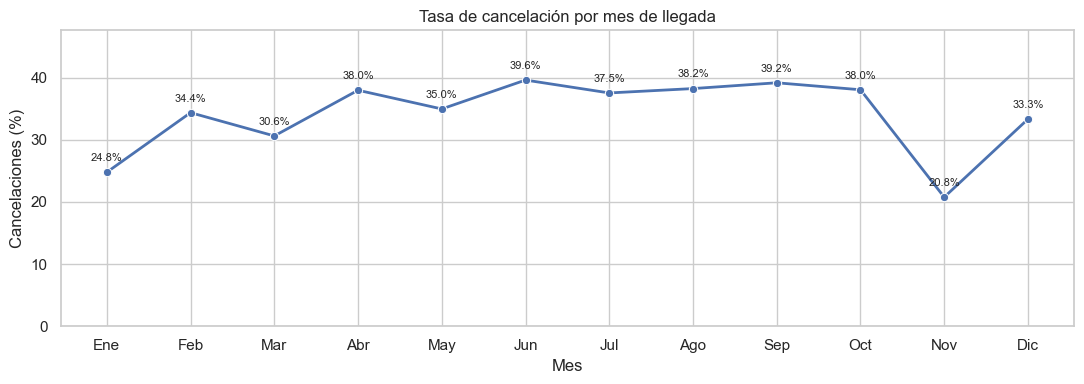

In [16]:
month_order = list(month_number.keys())
month_short = {
    "January": "Ene", "February": "Feb", "March": "Mar", "April": "Abr",
    "May": "May", "June": "Jun", "July": "Jul", "August": "Ago",
    "September": "Sep", "October": "Oct", "November": "Nov", "December": "Dic",
}
month_summary = (
    eda_train.groupby("arrival_date_month")["is_canceled"]
    .agg(reservas="size", tasa_cancelacion="mean")
    .reindex(month_order)
    .reset_index()
)
month_summary["mes"] = month_summary["arrival_date_month"].map(month_short)
month_summary["tasa_cancelacion_pct"] = 100 * month_summary["tasa_cancelacion"]
display(month_summary[["mes", "reservas", "tasa_cancelacion_pct"]].round(2))

fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(data=month_summary, x="mes", y="tasa_cancelacion_pct", marker="o", linewidth=2, color="#4C72B0", ax=ax)
for row in month_summary.itertuples():
    ax.annotate(f"{row.tasa_cancelacion_pct:.1f}%", (row.mes, row.tasa_cancelacion_pct), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set(title="Tasa de cancelación por mes de llegada", xlabel="Mes", ylabel="Cancelaciones (%)")
ax.set_ylim(0, month_summary["tasa_cancelacion_pct"].max() + 8)
plt.tight_layout()
plt.show()


**Conclusión recalculada.** Noviembre registra la tasa más baja (20,77%) y junio la más alta (39,61%). Entre julio y octubre las tasas se sitúan entre 37,53% y 39,17%. El mes puede aportar señal, pero noviembre y diciembre tienen menor cobertura y no deben interpretarse como una comparación estacional pura.


## 2.6 Segmentos de mercado

Se muestran tasas junto con el número de reservas. Esto permite detectar categorías con porcentajes extremos pero escaso soporte.


,market_segment,reservas,canceladas,tasa_cancelacion_pct
0,Undefined,2,2,100.00
1,Groups,12920,8011,62.00
2,Offline TA/TO,17199,5937,34.52
3,Online TA,29275,9797,33.47
4,Aviation,114,25,21.93
5,Corporate,3290,545,16.57
6,Direct,7155,1079,15.08
7,Complementary,434,49,11.29


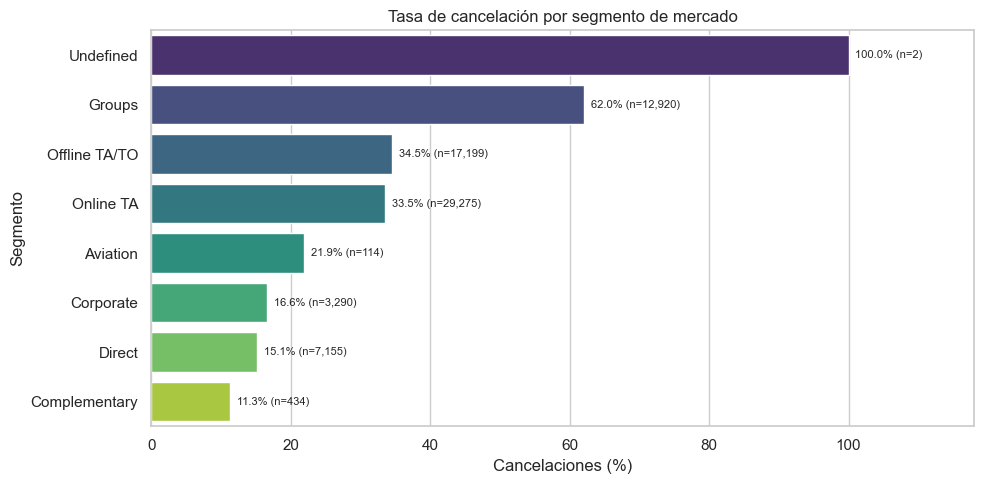

In [17]:
segment_summary = (
    eda_train.groupby("market_segment")["is_canceled"]
    .agg(reservas="size", canceladas="sum", tasa_cancelacion="mean")
    .sort_values("tasa_cancelacion", ascending=False)
    .reset_index()
)
segment_summary["tasa_cancelacion_pct"] = 100 * segment_summary["tasa_cancelacion"]
display(segment_summary[["market_segment", "reservas", "canceladas", "tasa_cancelacion_pct"]].round(2))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=segment_summary, y="market_segment", x="tasa_cancelacion_pct", hue="market_segment", legend=False, palette="viridis", ax=ax)
for patch, row in zip(ax.patches, segment_summary.itertuples()):
    ax.annotate(f"{row.tasa_cancelacion_pct:.1f}% (n={row.reservas:,})", (patch.get_width(), patch.get_y() + patch.get_height() / 2), xytext=(5, 0), textcoords="offset points", va="center", fontsize=8)
ax.set(title="Tasa de cancelación por segmento de mercado", xlabel="Cancelaciones (%)", ylabel="Segmento")
ax.set_xlim(0, 118)
plt.tight_layout()
plt.show()


**Conclusión recalculada.** `Groups` tiene 62,00% de cancelación sobre 12.920 reservas, frente a 15,08% en `Direct` y 16,57% en `Corporate`. `Undefined` alcanza 100%, pero contiene sólo 2 casos. `market_segment` conserva señal en desarrollo; las categorías escasas requieren codificación robusta.


## 2.7 Precio promedio por noche (`adr`)

Para que la forma principal sea visible, el histograma se limita al percentil 99; el boxplot omite extremos visualmente. Los cálculos de atípicos se realizan sobre todos los valores de entrenamiento y no se elimina ninguna fila.


,mediana,percentil_99,máximo,límite_IQR_superior,atípicos_IQR,porcentaje_atípicos,valores_no_positivos
0,90.0,236.0,5400.0,201.75,1993,2.83,1323


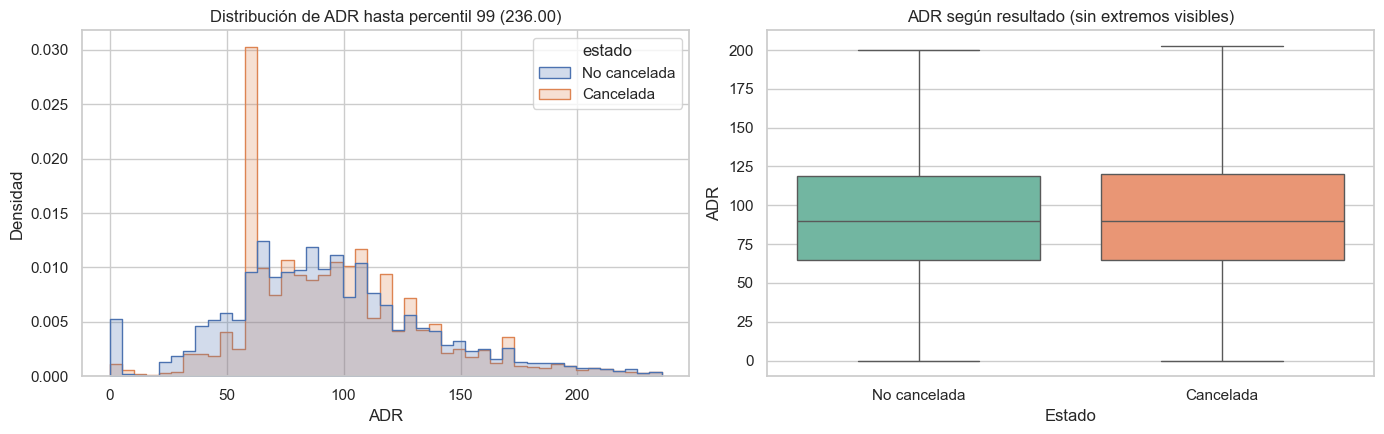

In [18]:
adr_q1, adr_q3 = eda_train["adr"].quantile([0.25, 0.75])
adr_iqr = adr_q3 - adr_q1
adr_lower = adr_q1 - 1.5 * adr_iqr
adr_upper = adr_q3 + 1.5 * adr_iqr
adr_outlier_mask = (eda_train["adr"] < adr_lower) | (eda_train["adr"] > adr_upper)
adr_p99 = eda_train["adr"].quantile(0.99)

adr_summary = pd.DataFrame({
    "mediana": [eda_train["adr"].median()],
    "percentil_99": [adr_p99],
    "máximo": [eda_train["adr"].max()],
    "límite_IQR_superior": [adr_upper],
    "atípicos_IQR": [int(adr_outlier_mask.sum())],
    "porcentaje_atípicos": [100 * adr_outlier_mask.mean()],
    "valores_no_positivos": [int((eda_train["adr"] <= 0).sum())],
})
display(adr_summary.round(2))

adr_visible = eda_train.loc[eda_train["adr"] <= adr_p99].copy()
adr_visible["estado"] = adr_visible["is_canceled"].map(cancel_labels)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=adr_visible, x="adr", hue="estado", bins=45, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set(title=f"Distribución de ADR hasta percentil 99 ({adr_p99:.2f})", xlabel="ADR", ylabel="Densidad")
sns.boxplot(data=eda_train.assign(estado=eda_train["is_canceled"].map(cancel_labels)), x="estado", y="adr", hue="estado", legend=False, showfliers=False, palette="Set2", ax=axes[1])
axes[1].set(title="ADR según resultado (sin extremos visibles)", xlabel="Estado", ylabel="ADR")
plt.tight_layout()
plt.show()


**Conclusión recalculada.** La mediana de `adr` es 90,00 y el percentil 99 es 236,00, mientras que el máximo llega a 5.400. La regla de 1,5 IQR marca 1.993 observaciones (2,83%) y existen 1.323 valores no positivos. Se mantiene el tratamiento robusto aprendido dentro de cada fold, sin eliminar automáticamente registros.


## 2.8 Auditoría de registros duplicados

El conteo de duplicados es una descripción de integridad sobre el dataset completo y no consulta el objetivo. En cambio, la comparación de cancelaciones entre filas únicas y repetidas se recalcula exclusivamente dentro del desarrollo definitivo.


,métrica,filas,porcentaje
0,Apariciones posteriores a la primera,31994,26.80
1,Filas pertenecientes a grupos repetidos,40165,33.64


,hotel,reservas,duplicadas,porcentaje
0,City Hotel,79330,25902,32.65
1,Resort Hotel,40060,6092,15.21


,tipo,reservas,canceladas,tasa_cancelacion_pct
0,Primera/única,49225,12095,24.57
1,Repetición posterior,21164,13350,63.08


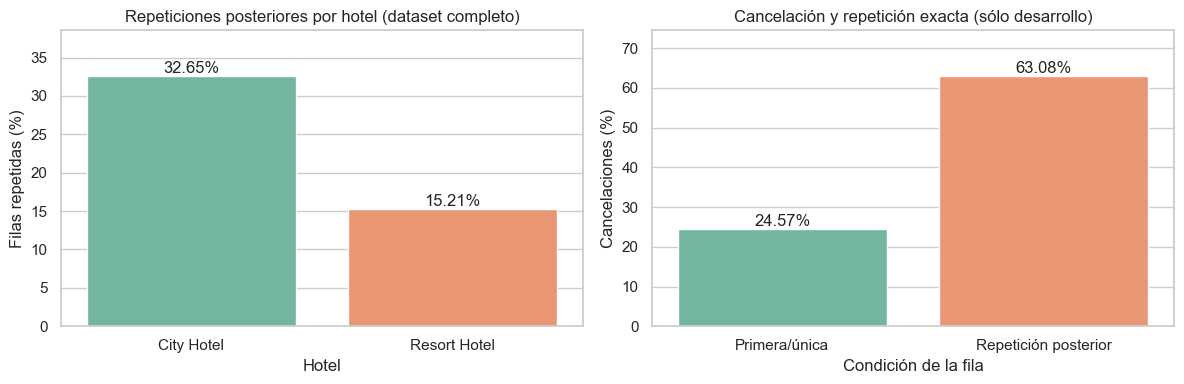

In [19]:
# Integridad general: descripción sobre el dataset completo, sin usar el objetivo.
duplicate_after_first = df.duplicated(keep="first")
duplicate_group_member = df.duplicated(keep=False)

duplicate_overview = pd.DataFrame({
    "métrica": ["Apariciones posteriores a la primera", "Filas pertenecientes a grupos repetidos"],
    "filas": [int(duplicate_after_first.sum()), int(duplicate_group_member.sum())],
    "porcentaje": [100 * duplicate_after_first.mean(), 100 * duplicate_group_member.mean()],
})
display(duplicate_overview.round(2))

duplicate_by_hotel = (
    pd.DataFrame({"hotel": df["hotel"], "duplicada": duplicate_after_first})
    .groupby("hotel")["duplicada"]
    .agg(reservas="size", duplicadas="sum", porcentaje="mean")
    .reset_index()
)
duplicate_by_hotel["porcentaje"] *= 100
display(duplicate_by_hotel.round(2))

# Asociación con la etiqueta: exclusivamente dentro del desarrollo definitivo.
eda_duplicate_after_first = eda_train.duplicated(keep="first")
duplicate_vs_cancel = (
    pd.DataFrame({
        "duplicada": eda_duplicate_after_first,
        "is_canceled": eda_train["is_canceled"],
    })
    .groupby("duplicada")["is_canceled"]
    .agg(reservas="size", canceladas="sum", tasa_cancelacion="mean")
    .reset_index()
)
duplicate_vs_cancel["tipo"] = duplicate_vs_cancel["duplicada"].map({
    False: "Primera/única", True: "Repetición posterior",
})
duplicate_vs_cancel["tasa_cancelacion_pct"] = 100 * duplicate_vs_cancel["tasa_cancelacion"]
display(duplicate_vs_cancel[["tipo", "reservas", "canceladas", "tasa_cancelacion_pct"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=duplicate_by_hotel, x="hotel", y="porcentaje", hue="hotel", legend=False, palette="Set2", ax=axes[0])
sns.barplot(data=duplicate_vs_cancel, x="tipo", y="tasa_cancelacion_pct", hue="tipo", legend=False, palette="Set2", ax=axes[1])
axes[0].set(title="Repeticiones posteriores por hotel (dataset completo)", xlabel="Hotel", ylabel="Filas repetidas (%)")
axes[1].set(title="Cancelación y repetición exacta (sólo desarrollo)", xlabel="Condición de la fila", ylabel="Cancelaciones (%)")
for ax, values in [(axes[0], duplicate_by_hotel["porcentaje"]), (axes[1], duplicate_vs_cancel["tasa_cancelacion_pct"])]:
    for patch, value in zip(ax.patches, values):
        ax.annotate(f"{value:.2f}%", (patch.get_x() + patch.get_width() / 2, patch.get_height()), ha="center", va="bottom")
    ax.set_ylim(0, max(values) * 1.18)
plt.tight_layout()
plt.show()


**Hallazgos y decisión recalculados.** En el dataset completo hay 31.994 apariciones posteriores a la primera (26,80%) y 40.165 filas pertenecientes a grupos repetidos (33,64%). Estos conteos estructurales no dependen del objetivo. Las repeticiones generales representan 32,65% de City Hotel y 15,21% de Resort Hotel.

Dentro del desarrollo definitivo, 21.164 filas son repeticiones posteriores. Su tasa de cancelación es 63,08%, frente a 24,57% en las 49.225 filas marcadas como primera/única. La asociación persiste sin consultar el test, pero la etiqueta “posterior” depende del orden y no prueba causalidad.

Se conserva la decisión de no eliminar automáticamente duplicados: sin identificador único no es posible distinguir errores de reservas legítimamente iguales. Un análisis de sensibilidad con deduplicación o ponderación queda pendiente y deberá realizarse sólo en desarrollo.


## 2.9 Decisión: modelo conjunto o modelos separados

Además de la diferencia en cancelación ya graficada, se comparan características operativas dentro de entrenamiento. Son descripciones, no pruebas causales.


In [20]:
hotel_profile = eda_train.groupby("hotel").agg(
    reservas=("is_canceled", "size"),
    tasa_cancelacion=("is_canceled", "mean"),
    mediana_lead_time=("lead_time", "median"),
    mediana_adr=("adr", "median"),
    media_noches_semana=("stays_in_week_nights", "mean"),
    media_noches_fin_semana=("stays_in_weekend_nights", "mean"),
    tasa_huesped_repetido=("is_repeated_guest", "mean"),
)
hotel_profile["media_noches_totales"] = hotel_profile.pop("media_noches_semana") + hotel_profile.pop("media_noches_fin_semana")
for column in ["tasa_cancelacion", "tasa_huesped_repetido"]:
    hotel_profile[column] *= 100
display(hotel_profile.round(2))


,reservas,tasa_cancelacion,mediana_lead_time,mediana_adr,tasa_huesped_repetido,media_noches_totales
hotel,,,,,,
City Hotel,46222,41.06,71.0,95.0,2.63,2.87
Resort Hotel,24167,26.76,59.0,74.0,3.29,4.30


En desarrollo, City Hotel mantiene mayor cancelación (41,06% frente a 26,76%), mayor mediana de anticipación (71 frente a 59 días) y mayor `adr` mediano (95 frente a 74). Resort Hotel presenta estadías medias más largas (4,30 frente a 2,87 noches) y una tasa algo mayor de huéspedes repetidos (3,29% frente a 2,63%).

**Decisión recalculada:** entrenar inicialmente un modelo conjunto y conservar `hotel` como predictor. Ambos establecimientos aportan suficientes observaciones y las diferencias pueden representarse mediante la variable hotel. Deberán informarse métricas separadas; sólo una validación dentro de desarrollo justificaría modelos distintos.


## 2.10 Cierre de la Etapa 2

- Las asociaciones predictivas y las decisiones basadas en `is_canceled` fueron recalculadas sobre el desarrollo definitivo.
- Los conteos generales del dataset se conservan sólo cuando describen estructura o integridad sin consultar el objetivo.
- `reservation_status` y `reservation_status_date` siguen excluidas por fuga.
- Se conserva la decisión de no eliminar duplicados automáticamente y de comenzar con un modelo conjunto; ambas se apoyan ahora en cifras de desarrollo.
- El test definitivo tuvo exposición en el EDA original. La corrección reduce la contaminación futura, pero no borra el conocimiento ya adquirido.


## 2.11 Revisiones pendientes de la Etapa 2

Los análisis de faltantes y depósitos usan exclusivamente `eda_train`, ahora definido como el desarrollo temporal definitivo. No se consulta el objetivo del test, no se imputan datos y no se eliminan variables o filas.


### 2.11.1 Valores faltantes y cancelación

Primero se distingue entre ausencia estructural —la variable no aplica a la reserva— y dato desconocido. Esta interpretación se basa en el significado de las columnas y debe confirmarse con el responsable del sistema de origen antes del modelado.


,variable,faltantes,faltantes_pct,cancelacion_faltante_pct,cancelacion_presente_pct,interpretacion
0,children,4,0.01,100.00,36.15,Faltante real: 0 ya representa una reserva sin...
1,country,351,0.50,13.11,36.26,Faltante real/desconocido: no hay un código de...
2,agent,9179,13.04,19.04,38.71,No aplica probable: reserva sin agencia identi...
3,company,66465,94.43,37.34,15.93,No aplica probable: reserva sin empresa identi...


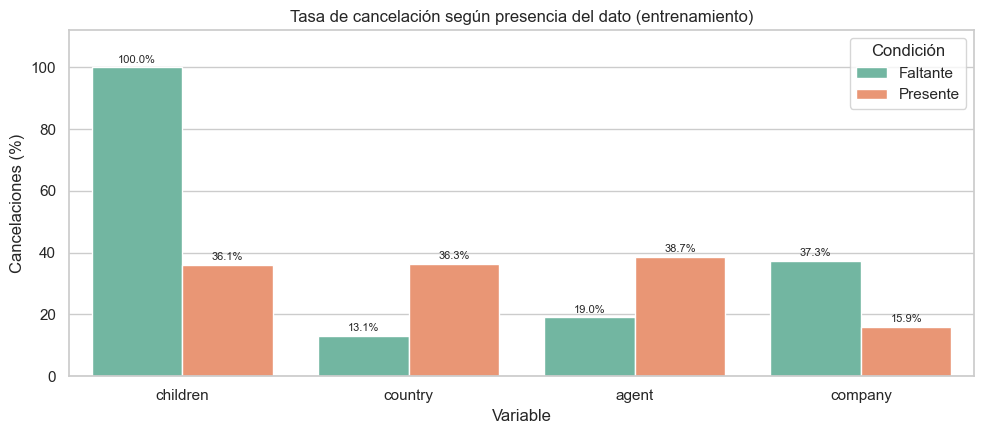

In [21]:
missing_interpretation = {
    "children": "Faltante real: 0 ya representa una reserva sin niños.",
    "country": "Faltante real/desconocido: no hay un código de país informado.",
    "agent": "No aplica probable: reserva sin agencia identificada.",
    "company": "No aplica probable: reserva sin empresa identificada.",
}

missing_rows = []
for column, interpretation in missing_interpretation.items():
    is_missing = eda_train[column].isna()
    missing_rows.append({
        "variable": column,
        "faltantes": int(is_missing.sum()),
        "faltantes_pct": 100 * is_missing.mean(),
        "cancelacion_faltante_pct": 100 * eda_train.loc[is_missing, "is_canceled"].mean(),
        "cancelacion_presente_pct": 100 * eda_train.loc[~is_missing, "is_canceled"].mean(),
        "interpretacion": interpretation,
    })

missing_summary = pd.DataFrame(missing_rows)
display(missing_summary.round(2))

missing_plot = missing_summary.melt(
    id_vars="variable",
    value_vars=["cancelacion_faltante_pct", "cancelacion_presente_pct"],
    var_name="condicion",
    value_name="tasa_cancelacion_pct",
)
missing_plot["condicion"] = missing_plot["condicion"].map({
    "cancelacion_faltante_pct": "Faltante",
    "cancelacion_presente_pct": "Presente",
})

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=missing_plot, x="variable", y="tasa_cancelacion_pct", hue="condicion", palette="Set2", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=8)
ax.set(
    title="Tasa de cancelación según presencia del dato (entrenamiento)",
    xlabel="Variable",
    ylabel="Cancelaciones (%)",
)
ax.set_ylim(0, 112)
ax.legend(title="Condición")
plt.tight_layout()
plt.show()


**Conclusión recalculada sobre faltantes.** En desarrollo faltan 4 valores de `children` (0,01%), 351 de `country` (0,50%), 9.179 de `agent` (13,04%) y 66.465 de `company` (94,43%). Los cuatro casos sin `children` están cancelados, pero no permiten inferencias estables. La cancelación es 13,11% cuando falta `country` frente a 36,26% cuando está presente; 19,04% frente a 38,71% para `agent`; y 37,34% frente a 15,93% para `company`.

La ausencia conserva señal sin demostrar causalidad. `children` y `country` se tratan como faltantes reales; `agent` y `company` como “No aplica” probable. Estas decisiones se implementan dentro del pipeline y sus parámetros se aprenden en cada fold.


### 2.11.2 Investigación de depósitos `Non Refund`

Se comprueba si la tasa extrema está concentrada en un hotel o período y si las repeticiones exactas explican parte del resultado. Las duplicaciones se calculan usando las 32 columnas originales.


,hotel,reservas,canceladas,tasa_cancelacion_pct
0,City Hotel,8232,8209,99.72
1,Resort Hotel,1325,1264,95.40


,periodo,reservas,canceladas,tasa_cancelacion,tasa_cancelacion_pct
0,2015-07,230,230,1.00,100.00
1,2015-08,580,580,1.00,100.00
2,2015-09,1203,1203,1.00,100.00
3,2015-10,1081,1074,0.99,99.35
4,2015-11,88,87,0.99,98.86
5,2015-12,485,484,1.00,99.79
6,2016-01,198,198,1.00,100.00
7,2016-02,502,501,1.00,99.80
8,2016-03,507,504,0.99,99.41
9,2016-04,944,895,0.95,94.81


,market_segment,reservas,canceladas,tasa_cancelacion,tasa_cancelacion_pct
0,Groups,5880,5826,0.99,99.08
1,Offline TA/TO,3476,3473,1.00,99.91
2,Corporate,137,115,0.84,83.94
3,Online TA,51,49,0.96,96.08
4,Direct,13,10,0.77,76.92


,métrica,filas,porcentaje_sobre_non_refund,tasa_cancelacion_pct
0,Todas las filas Non Refund,9557,100.00,99.12
1,Repeticiones posteriores exactas,8914,93.27,99.60
2,Patrones únicos Non Refund,643,6.73,92.53


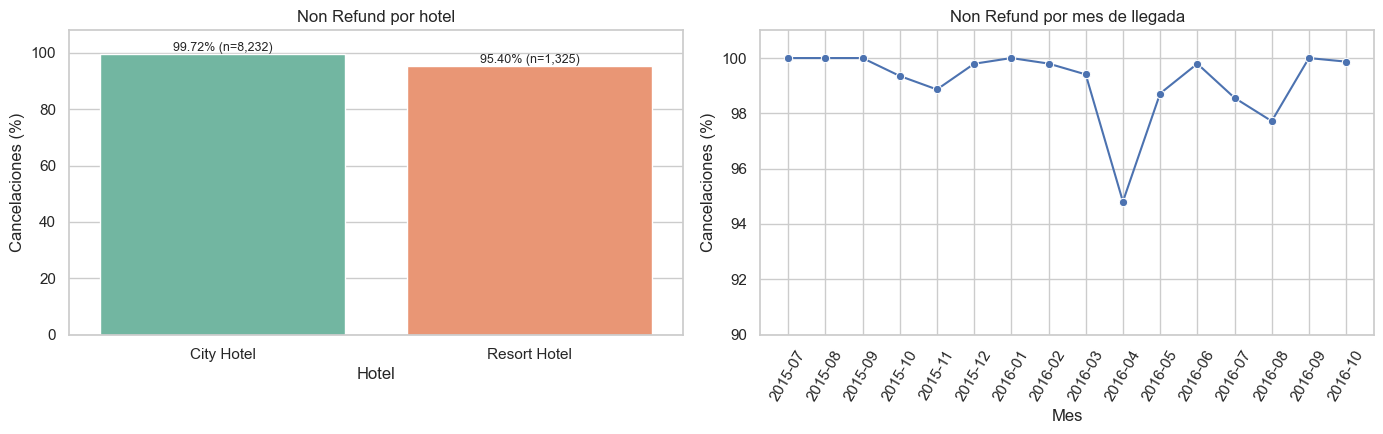

In [22]:
non_refund = eda_train.loc[eda_train["deposit_type"] == "Non Refund"].copy()
non_refund["arrival_date"] = arrival_date.loc[non_refund.index]

non_refund_hotel = (
    non_refund.groupby("hotel")["is_canceled"]
    .agg(reservas="size", canceladas="sum", tasa_cancelacion="mean")
    .reset_index()
)
non_refund_hotel["tasa_cancelacion_pct"] = 100 * non_refund_hotel["tasa_cancelacion"]

non_refund_period = (
    non_refund.assign(periodo=non_refund["arrival_date"].dt.to_period("M").astype(str))
    .groupby("periodo")["is_canceled"]
    .agg(reservas="size", canceladas="sum", tasa_cancelacion="mean")
    .reset_index()
)
non_refund_period["tasa_cancelacion_pct"] = 100 * non_refund_period["tasa_cancelacion"]

non_refund_segment = (
    non_refund.groupby("market_segment")["is_canceled"]
    .agg(reservas="size", canceladas="sum", tasa_cancelacion="mean")
    .sort_values("reservas", ascending=False)
    .reset_index()
)
non_refund_segment["tasa_cancelacion_pct"] = 100 * non_refund_segment["tasa_cancelacion"]

non_refund_repeated = non_refund.duplicated(subset=df.columns, keep="first")
non_refund_unique = non_refund.drop_duplicates(subset=df.columns, keep="first")
non_refund_audit = pd.DataFrame({
    "métrica": [
        "Todas las filas Non Refund",
        "Repeticiones posteriores exactas",
        "Patrones únicos Non Refund",
    ],
    "filas": [len(non_refund), int(non_refund_repeated.sum()), len(non_refund_unique)],
    "porcentaje_sobre_non_refund": [
        100.0,
        100 * non_refund_repeated.mean(),
        100 * len(non_refund_unique) / len(non_refund),
    ],
    "tasa_cancelacion_pct": [
        100 * non_refund["is_canceled"].mean(),
        100 * non_refund.loc[non_refund_repeated, "is_canceled"].mean(),
        100 * non_refund_unique["is_canceled"].mean(),
    ],
})

display(non_refund_hotel[["hotel", "reservas", "canceladas", "tasa_cancelacion_pct"]].round(2))
display(non_refund_period.round(2))
display(non_refund_segment.round(2))
display(non_refund_audit.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=non_refund_hotel, x="hotel", y="tasa_cancelacion_pct", hue="hotel", legend=False, palette="Set2", ax=axes[0])
for patch, row in zip(axes[0].patches, non_refund_hotel.itertuples()):
    axes[0].annotate(
        f"{row.tasa_cancelacion_pct:.2f}% (n={row.reservas:,})",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        ha="center", va="bottom", fontsize=9,
    )
axes[0].set(title="Non Refund por hotel", xlabel="Hotel", ylabel="Cancelaciones (%)", ylim=(0, 108))

sns.lineplot(data=non_refund_period, x="periodo", y="tasa_cancelacion_pct", marker="o", color="#4C72B0", ax=axes[1])
axes[1].set(title="Non Refund por mes de llegada", xlabel="Mes", ylabel="Cancelaciones (%)", ylim=(90, 101))
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()


**Hallazgos recalculados.** De las 9.557 reservas `Non Refund` del desarrollo, 9.473 están canceladas (99,12%). El patrón persiste en City Hotel —99,72% sobre 8.232 reservas— y Resort Hotel —95,40% sobre 1.325—, y en todos los meses observados, con tasas entre 94,81% y 100%.

La categoría se concentra en `Groups` (5.880 reservas, 99,08% canceladas) y `Offline TA/TO` (3.476, 99,91%). Hay 8.914 repeticiones exactas posteriores (93,27%), pero entre los 643 patrones únicos la cancelación sigue siendo 92,53%; la duplicación amplifica el fenómeno sin explicarlo por completo.

**Disponibilidad y posible fuga.** `deposit_type` no revela directamente el resultado como `reservation_status`, pero no puede confirmarse que su valor del archivo sea el registrado al crear la reserva. Se conserva en el modelo principal como variable condicionalmente admisible y queda pendiente una ablación específica. La asociación extrema no basta para descartarla ni para afirmar causalidad.


### 2.11.3 Benchmark cronológico histórico por llegada

Esta validación por fecha de llegada se conserva sólo como antecedente metodológico. Se reconstruye dentro del desarrollo definitivo y no incluye noviembre–diciembre de 2016. La estrategia canónica para modelar es la de seis folds por creación aproximada con purga de etiquetas, definida en la Etapa 3.


In [23]:
chronological_fold_specs = [
    ("2015-12-31", "2016-01-01", "2016-02-29"),
    ("2016-02-29", "2016-03-01", "2016-04-30"),
    ("2016-04-30", "2016-05-01", "2016-06-30"),
    ("2016-06-30", "2016-07-01", "2016-08-31"),
    ("2016-08-31", "2016-09-01", "2016-09-30"),
    ("2016-09-30", "2016-10-01", "2016-10-31"),
]

eda_train_dates = arrival_date.loc[eda_train.index]
chronological_folds = []
chronological_fold_rows = []
validation_indices_seen = set()

for fold_number, (train_end_text, validation_start_text, validation_end_text) in enumerate(chronological_fold_specs, start=1):
    train_end = pd.Timestamp(train_end_text)
    validation_start = pd.Timestamp(validation_start_text)
    validation_end = pd.Timestamp(validation_end_text)

    fold_train_index = eda_train_dates.index[eda_train_dates <= train_end]
    fold_validation_index = eda_train_dates.index[eda_train_dates.between(validation_start, validation_end)]
    train_dates = eda_train_dates.loc[fold_train_index]
    validation_dates = eda_train_dates.loc[fold_validation_index]

    assert train_dates.max() < validation_dates.min()
    assert set(fold_train_index).isdisjoint(fold_validation_index)
    assert set(train_dates.unique()).isdisjoint(validation_dates.unique())
    assert validation_dates.max() < CREATION_TEST_START
    assert validation_indices_seen.isdisjoint(fold_validation_index)
    assert (set(fold_train_index) | set(fold_validation_index)).isdisjoint(creation_final_test_index)
    validation_indices_seen.update(fold_validation_index)

    chronological_folds.append((fold_train_index.to_numpy(), fold_validation_index.to_numpy()))
    chronological_fold_rows.append({
        "fold": fold_number,
        "entrenamiento_desde": train_dates.min().date(),
        "entrenamiento_hasta": train_dates.max().date(),
        "filas_entrenamiento": len(fold_train_index),
        "cancelacion_entrenamiento_pct": 100 * eda_train.loc[fold_train_index, "is_canceled"].mean(),
        "validacion_desde": validation_dates.min().date(),
        "validacion_hasta": validation_dates.max().date(),
        "filas_validacion": len(fold_validation_index),
        "cancelacion_validacion_pct": 100 * eda_train.loc[fold_validation_index, "is_canceled"].mean(),
        "fechas_compartidas": 0,
    })

chronological_fold_summary = pd.DataFrame(chronological_fold_rows)
display(chronological_fold_summary.round(2))
print(f"Folds históricos por llegada preparados dentro de desarrollo: {len(chronological_folds)}")
print("Filas del test definitivo utilizadas: 0")


,fold,entrenamiento_desde,entrenamiento_hasta,filas_entrenamiento,cancelacion_entrenamiento_pct,validacion_desde,validacion_hasta,filas_validacion,cancelacion_validacion_pct,fechas_compartidas
0,1,2015-07-01,2015-12-31,21996,37.02,2016-01-01,2016-02-29,6139,30.85,0
1,2,2015-07-01,2016-02-29,28135,35.67,2016-03-01,2016-04-30,10252,34.51,0
2,3,2015-07-01,2016-04-30,38387,35.36,2016-05-01,2016-06-30,10770,37.24,0
3,4,2015-07-01,2016-06-30,49157,35.77,2016-07-01,2016-08-31,9635,34.50,0
4,5,2015-07-01,2016-08-31,58792,35.56,2016-09-01,2016-09-30,5394,37.49,0
5,6,2015-07-01,2016-09-30,64186,35.73,2016-10-01,2016-10-31,6203,40.53,0


Folds históricos por llegada preparados dentro de desarrollo: 6
Filas del test definitivo utilizadas: 0


**Conclusión sobre el benchmark histórico.** Los seis bloques por llegada se reconstruyeron únicamente dentro de desarrollo: entrenan con 21.996–64.186 reservas y validan con 5.394–10.770, sin filas del test definitivo. Se conservan como antecedente y comprobación del pipeline, pero la selección de modelos usa exclusivamente `creation_time_folds` con purga.


### 2.11.4 Estado al cerrar las revisiones

- **Faltantes y depósitos:** cifras recalculadas sólo sobre desarrollo.
- **Benchmark por llegada:** conservado como antecedente, sin filas del test definitivo.
- **Validación canónica:** seis folds por creación aproximada con purga, definidos posteriormente y usados en la Etapa 4.
- **Exposición histórica:** 2.923 filas del test aparecieron en el EDA original; esta limitación no puede deshacerse y queda documentada.


# Etapa 3 - Preparación de Datos y Feature Engineering

## 3.1 Momento de predicción y alcance

**Momento formal de predicción:** inmediatamente después de registrar una nueva reserva en el PMS y antes de que ocurran pagos posteriores, cambios, asignaciones operativas, confirmaciones de lista de espera, cancelaciones o llegada del huésped. El objetivo es estimar el riesgo futuro de `is_canceled` utilizando únicamente información que debería existir en ese instante.

Esta definición es más temprana que el punto temporal del dataset. El artículo técnico indica que el punto de captura de cada observación fue el día anterior a la llegada y que, cuando existían cambios, se tomó el valor del historial de la reserva en ese momento. También advierte que personas, duración, habitación, comida y país pueden modificarse o conocerse más tarde. Por tanto, la fecha de extracción no prueba que cada valor observado sea exactamente el valor original al registrar la reserva.

Fuentes: [Antonio, Almeida y Nunes (2019), artículo técnico en PMC](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/) y [DOI 10.1016/j.dib.2018.11.126](https://doi.org/10.1016/j.dib.2018.11.126).


### Auditoría de disponibilidad temporal

Se adopta un criterio conservador. Los campos que describen la solicitud inicial o antecedentes previos se incluyen, aunque se registra la limitación de que el archivo puede contener su valor actualizado. Los campos cuya propia definición usa hechos posteriores se excluyen del modelo principal. Las exclusiones no eliminan columnas de `df`; sólo controlan qué recibe el pipeline.


In [24]:
availability_rows = [
    ("hotel", "Incluir", "El establecimiento se conoce al registrar la reserva."),
    ("lead_time y fecha de llegada", "Incluir con cautela", "Se calculan/conocen al reservar; la llegada pudo modificarse después."),
    ("adults, children, babies", "Incluir con cautela", "Composición solicitada al reservar; el artículo indica que puede cambiar."),
    ("stays_in_weekend_nights, stays_in_week_nights", "Incluir con cautela", "Duración solicitada al reservar; puede cambiar posteriormente."),
    ("meal, reserved_room_type", "Incluir con cautela", "Preferencias de la reserva inicial; el archivo puede reflejar cambios."),
    ("market_segment, distribution_channel, agent, company, customer_type", "Incluir", "Canal y responsables asociados a la creación; NULL en agent/company significa No aplica."),
    ("is_repeated_guest, previous_*", "Incluir", "El artículo los define usando historial anterior a la reserva actual."),
    ("country", "Excluir provisionalmente", "El artículo advierte que puede conocerse correctamente recién en el check-in."),
    ("assigned_room_type", "Excluir", "Asignación operativa que puede responder a sobreventa o solicitudes posteriores."),
    ("booking_changes", "Excluir", "Cuenta cambios desde la creación hasta check-in o cancelación."),
    ("deposit_type", "Excluir provisionalmente", "Se calcula con pagos registrados antes de llegada o cancelación, no necesariamente al crear."),
    ("days_in_waiting_list", "Excluir", "Sólo se conoce cuando la reserva es confirmada al cliente."),
    ("adr", "Excluir provisionalmente", "Se calcula con transacciones de alojamiento y puede reflejar cambios posteriores."),
    ("required_car_parking_spaces, total_of_special_requests", "Excluir provisionalmente", "El archivo usa BO/BL y no permite confirmar que sean los valores de creación."),
    ("reservation_status, reservation_status_date", "Excluir por fuga directa", "Describen el resultado final y cuándo se fijó."),
    ("is_canceled", "Objetivo", "Variable a predecir; nunca entra en X."),
]
availability_audit = pd.DataFrame(availability_rows, columns=["variable_o_familia", "decisión", "justificación"])
display(availability_audit)

TARGET_COLUMN = "is_canceled"
DIRECT_LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]
PROVISIONALLY_EXCLUDED_COLUMNS = [
    "country",
    "assigned_room_type",
    "booking_changes",
    "deposit_type",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests",
]

BASE_NUMERIC_FEATURES = [
    "lead_time",
    "arrival_date_year",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
]
BASE_CATEGORICAL_FEATURES = [
    "hotel",
    "arrival_date_month",
    "meal",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "customer_type",
]
NOT_APPLICABLE_CATEGORICAL_FEATURES = ["agent", "company"]
BASE_MODEL_FEATURES = BASE_NUMERIC_FEATURES + BASE_CATEGORICAL_FEATURES + NOT_APPLICABLE_CATEGORICAL_FEATURES

assert TARGET_COLUMN not in BASE_MODEL_FEATURES
assert set(DIRECT_LEAKAGE_COLUMNS).isdisjoint(BASE_MODEL_FEATURES)
assert set(PROVISIONALLY_EXCLUDED_COLUMNS).isdisjoint(BASE_MODEL_FEATURES)
print(f"Variables originales admitidas en el modelo principal: {len(BASE_MODEL_FEATURES)}")
print(f"Variables excluidas por fuga o incertidumbre temporal: {len(DIRECT_LEAKAGE_COLUMNS + PROVISIONALLY_EXCLUDED_COLUMNS)}")


,variable_o_familia,decisión,justificación
0,hotel,Incluir,El establecimiento se conoce al registrar la r...
1,lead_time y fecha de llegada,Incluir con cautela,Se calculan/conocen al reservar; la llegada pu...
2,"adults, children, babies",Incluir con cautela,Composición solicitada al reservar; el artícul...
3,"stays_in_weekend_nights, stays_in_week_nights",Incluir con cautela,Duración solicitada al reservar; puede cambiar...
4,"meal, reserved_room_type",Incluir con cautela,Preferencias de la reserva inicial; el archivo...
5,"market_segment, distribution_channel, agent, c...",Incluir,Canal y responsables asociados a la creación; ...
6,"is_repeated_guest, previous_*",Incluir,El artículo los define usando historial anteri...
7,country,Excluir provisionalmente,El artículo advierte que puede conocerse corre...
8,assigned_room_type,Excluir,Asignación operativa que puede responder a sob...
9,booking_changes,Excluir,Cuenta cambios desde la creación hasta check-i...


Variables originales admitidas en el modelo principal: 21
Variables excluidas por fuga o incertidumbre temporal: 10


**Decisión sobre la limitación del snapshot.** Los campos de huéspedes, estadía y habitación reservada son necesarios para crear una reserva y, por lo tanto, están conceptualmente disponibles en el momento definido. Se usan bajo esa condición operativa. Sin embargo, el dataset no conserva simultáneamente el valor inicial y el actualizado. Esta limitación no puede corregirse con preprocesamiento y deberá mencionarse en el informe; también se planifica una ablación de estas familias.

`deposit_type` no se incorpora al modelo principal pese a su señal en el EDA: el artículo confirma que se calcula a partir de pagos registrados antes de la llegada **o de la cancelación**, lo que no garantiza disponibilidad al crear la reserva. Se conserva únicamente para un futuro experimento de sensibilidad, separado del experimento deliberado de fuga con `reservation_status` y `reservation_status_date`.


## 3.2 Ocho variables nuevas

Las transformaciones son determinísticas por fila: no consultan `is_canceled`, otras reservas ni períodos futuros.

| Variable | Cálculo | Aporte potencial y disponibilidad |
|---|---|---|
| `total_guests` | `adults + children + babies` | Resume el tamaño del grupo registrado. Disponible con la composición inicial. |
| `total_nights` | noches de semana + fin de semana | Resume duración y evita depender de dos campos separados. Disponible con la estadía solicitada. |
| `weekend_ratio` | noches de fin de semana / noches totales | Distingue estadías laborales y de ocio. Si no hay noches, queda faltante para imputación. |
| `has_children` | 1 si hay niños o bebés; 0 en otro caso | Captura reservas familiares sin asumir linealidad en los conteos. |
| `lead_time_category` | 0–7, 8–30, 31–90, 91–180, 181–365 o >365 días | Representa la asociación no lineal observada en EDA. Usa anticipación conocida al reservar. |
| `total_previous_bookings` | cancelaciones previas + reservas previas no canceladas | Mide experiencia histórica disponible antes de la reserva actual. |
| `previous_cancellation_rate` | cancelaciones previas / total previo; 0 sin historial | Resume propensión histórica sin usar el resultado actual. |
| `arrival_season` | invierno, primavera, verano u otoño según el mes | Resume estacionalidad en Portugal (hemisferio norte). Usa la fecha solicitada. |

Las variables derivadas de composición, estadía y llegada comparten la limitación del snapshot actualizado descrita arriba. Ninguna reproduce el objetivo actual.


In [25]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler


ENGINEERED_NUMERIC_FEATURES = [
    "total_guests",
    "total_nights",
    "weekend_ratio",
    "has_children",
    "total_previous_bookings",
    "previous_cancellation_rate",
]
ENGINEERED_CATEGORICAL_FEATURES = ["lead_time_category", "arrival_season"]
ENGINEERED_FEATURES = ENGINEERED_NUMERIC_FEATURES + ENGINEERED_CATEGORICAL_FEATURES


class HotelBookingFeatureEngineer(BaseEstimator, TransformerMixin):
    # Crea variables por fila sin aprender estadísticas ni consultar el objetivo.

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        data = X.copy()

        data["total_guests"] = data[["adults", "children", "babies"]].sum(axis=1, min_count=3)
        data["total_nights"] = data["stays_in_weekend_nights"] + data["stays_in_week_nights"]
        data["weekend_ratio"] = data["stays_in_weekend_nights"].div(
            data["total_nights"].where(data["total_nights"] > 0)
        )

        children_or_babies = (data["children"].fillna(0) + data["babies"]) > 0
        data["has_children"] = children_or_babies.astype(float)
        unknown_children = data["children"].isna() & data["babies"].eq(0)
        data.loc[unknown_children, "has_children"] = np.nan

        data["lead_time_category"] = pd.cut(
            data["lead_time"],
            bins=[-np.inf, 7, 30, 90, 180, 365, np.inf],
            labels=["0-7", "8-30", "31-90", "91-180", "181-365", ">365"],
        ).astype("object")

        data["total_previous_bookings"] = (
            data["previous_cancellations"] + data["previous_bookings_not_canceled"]
        )
        data["previous_cancellation_rate"] = np.divide(
            data["previous_cancellations"],
            data["total_previous_bookings"],
            out=np.zeros(len(data), dtype=float),
            where=data["total_previous_bookings"].to_numpy() > 0,
        )

        season_by_month = {
            "December": "Winter", "January": "Winter", "February": "Winter",
            "March": "Spring", "April": "Spring", "May": "Spring",
            "June": "Summer", "July": "Summer", "August": "Summer",
            "September": "Autumn", "October": "Autumn", "November": "Autumn",
        }
        data["arrival_season"] = data["arrival_date_month"].map(season_by_month)
        return data


class QuantileClipper(BaseEstimator, TransformerMixin):
    # Recorta columnas a cuantiles aprendidos exclusivamente durante fit.

    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        values = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.quantile(values, self.lower_quantile, axis=0)
        self.upper_bounds_ = np.quantile(values, self.upper_quantile, axis=0)
        return self

    def transform(self, X):
        values = np.asarray(X, dtype=float)
        return np.clip(values, self.lower_bounds_, self.upper_bounds_)


In [26]:
feature_engineer = HotelBookingFeatureEngineer()
engineered_preview = feature_engineer.transform(eda_train[BASE_MODEL_FEATURES].head(8))
display(engineered_preview[ENGINEERED_FEATURES])

engineered_train_check = feature_engineer.transform(eda_train[BASE_MODEL_FEATURES])
feature_check = pd.DataFrame({
    "variable": ENGINEERED_FEATURES,
    "faltantes": [int(engineered_train_check[column].isna().sum()) for column in ENGINEERED_FEATURES],
    "valores_unicos": [int(engineered_train_check[column].nunique(dropna=True)) for column in ENGINEERED_FEATURES],
})
display(feature_check)

assert len(ENGINEERED_FEATURES) == 8
assert engineered_train_check["weekend_ratio"].dropna().between(0, 1).all()
assert engineered_train_check["previous_cancellation_rate"].between(0, 1).all()
assert (engineered_train_check["total_previous_bookings"] >= 0).all()
print("Las ocho variables fueron creadas sin usar is_canceled.")


,total_guests,total_nights,weekend_ratio,has_children,total_previous_bookings,previous_cancellation_rate,lead_time_category,arrival_season
0,2.0,0,NaN,0.0,0,0.0,181-365,Summer
1,2.0,0,NaN,0.0,0,0.0,>365,Summer
2,1.0,1,0.0,0.0,0,0.0,0-7,Summer
3,1.0,1,0.0,0.0,0,0.0,8-30,Summer
4,2.0,2,0.0,0.0,0,0.0,8-30,Summer
5,2.0,2,0.0,0.0,0,0.0,8-30,Summer
6,2.0,2,0.0,0.0,0,0.0,0-7,Summer
7,2.0,2,0.0,0.0,0,0.0,8-30,Summer


,variable,faltantes,valores_unicos
0,total_guests,4,15
1,total_nights,0,40
2,weekend_ratio,481,41
3,has_children,4,2
4,total_previous_bookings,0,54
5,previous_cancellation_rate,0,74
6,lead_time_category,0,6
7,arrival_season,0,4


Las ocho variables fueron creadas sin usar is_canceled.


## 3.3 Preprocesamiento sin fuga

- `children` es un faltante real y se imputa con la mediana aprendida en el entrenamiento de cada fold.
- Los demás numéricos usan la misma estrategia robusta; las proporciones indefinidas, como `weekend_ratio` en una estadía de cero noches, se imputan dentro del fold.
- `agent` y `company` son identificadores categóricos. El artículo especifica que `NULL` significa “No aplica”; se codifica como la categoría numérica reservada `-1`, no como un valor estadísticamente imputado.
- El resto de las categorías usa moda del fold y `OneHotEncoder(handle_unknown="ignore")` para admitir categorías futuras.
- Los numéricos con extremos plausibles se recortan a los percentiles 1 y 99 aprendidos en el fold y luego se escalan con `RobustScaler`. No se elimina ninguna reserva.
- Todas las operaciones quedan dentro de `Pipeline`/`ColumnTransformer`; nunca se ajusta el preprocesador antes de separar entrenamiento y validación.


In [27]:
CLIPPED_NUMERIC_FEATURES = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "total_guests",
    "total_nights",
]
REGULAR_NUMERIC_FEATURES = [
    column
    for column in BASE_NUMERIC_FEATURES + ENGINEERED_NUMERIC_FEATURES
    if column not in CLIPPED_NUMERIC_FEATURES
]
ALL_CATEGORICAL_FEATURES = BASE_CATEGORICAL_FEATURES + ENGINEERED_CATEGORICAL_FEATURES

clipped_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("outlier_clipper", QuantileClipper(lower_quantile=0.01, upper_quantile=0.99)),
    ("scaler", RobustScaler()),
])
regular_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])
not_applicable_pipeline = Pipeline([
    ("not_applicable", SimpleImputer(strategy="constant", fill_value=-1.0)),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])

preprocessor_with_engineering = ColumnTransformer(
    transformers=[
        ("numeric_clipped", clipped_numeric_pipeline, CLIPPED_NUMERIC_FEATURES),
        ("numeric_regular", regular_numeric_pipeline, REGULAR_NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, ALL_CATEGORICAL_FEATURES),
        ("not_applicable", not_applicable_pipeline, NOT_APPLICABLE_CATEGORICAL_FEATURES),
    ],
    remainder="drop",
)

main_preprocessing_pipeline = Pipeline([
    ("feature_engineering", HotelBookingFeatureEngineer()),
    ("preprocessing", preprocessor_with_engineering),
])

assert set(ENGINEERED_FEATURES).issubset(
    set(CLIPPED_NUMERIC_FEATURES + REGULAR_NUMERIC_FEATURES + ALL_CATEGORICAL_FEATURES)
)
print(main_preprocessing_pipeline)


Pipeline(steps=[('feature_engineering', HotelBookingFeatureEngineer()),
                ('preprocessing',
                 ColumnTransformer(transformers=[('numeric_clipped',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('outlier_clipper',
                                                                   QuantileClipper()),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['lead_time',
                                                   'stays_in_weekend_nights',
                                                   'stays_in_week_nights',
                                                   'adults', 'children',
                   

### Comprobación histórica en un fold, sin entrenar un modelo

Se clona el pipeline y se ajustan sólo sus transformaciones con el entrenamiento del primer fold por llegada, ya restringido al desarrollo definitivo. La prueba verifica compatibilidad y dimensiones sin usar filas del test. La estrategia canónica por creación se comprueba posteriormente en los seis folds correspondientes.


In [28]:
first_fold_train_index, first_fold_validation_index = chronological_folds[0]

X_first_fold_train = df.loc[first_fold_train_index, BASE_MODEL_FEATURES]
X_first_fold_validation = df.loc[first_fold_validation_index, BASE_MODEL_FEATURES]

first_fold_preprocessor = clone(main_preprocessing_pipeline)
X_first_fold_train_ready = first_fold_preprocessor.fit_transform(X_first_fold_train)
X_first_fold_validation_ready = first_fold_preprocessor.transform(X_first_fold_validation)

pipeline_check = pd.DataFrame({
    "bloque": ["Entrenamiento fold 1", "Validación fold 1"],
    "filas_entrada": [len(X_first_fold_train), len(X_first_fold_validation)],
    "filas_salida": [X_first_fold_train_ready.shape[0], X_first_fold_validation_ready.shape[0]],
    "columnas_salida": [X_first_fold_train_ready.shape[1], X_first_fold_validation_ready.shape[1]],
})
display(pipeline_check)

assert X_first_fold_train_ready.shape[0] == len(first_fold_train_index)
assert X_first_fold_validation_ready.shape[0] == len(first_fold_validation_index)
assert X_first_fold_train_ready.shape[1] == X_first_fold_validation_ready.shape[1]
assert set(first_fold_train_index).isdisjoint(first_fold_validation_index)
assert set(first_fold_train_index).isdisjoint(creation_final_test_index)
assert set(first_fold_validation_index).isdisjoint(creation_final_test_index)

print("Pipeline verificado en el fold 1; no se entrenó ningún modelo.")


,bloque,filas_entrada,filas_salida,columnas_salida
0,Entrenamiento fold 1,21996,21996,339
1,Validación fold 1,6139,6139,339


Pipeline verificado en el fold 1; no se entrenó ningún modelo.


## 3.4 Integración con los folds temporales

Los folds por llegada se mantienen únicamente como comprobación histórica dentro del desarrollo definitivo. El pipeline siempre se ajusta dentro del entrenamiento de cada fold. La selección de modelos se realiza más adelante con `creation_time_folds`, que es la estrategia coherente con el momento de predicción.


## 3.5 Próximos experimentos (documentados, no ejecutados)

1. **Variables originales:** pipeline sin las ocho variables nuevas.
2. **Originales + ingeniería:** pipeline principal con las ocho variables.
3. **Ablación:** retirar una familia por vez, incluida una variante sin `deposit_type` y otros campos de disponibilidad incierta.
4. **Selección de variables:** ajustar el selector dentro de cada fold.
5. **Fuga controlada:** incorporar `reservation_status` sólo como demostración pedagógica en desarrollo, nunca como modelo válido.

Todos estos experimentos deben usar los mismos `creation_time_folds`. El test no participará en selección, ablación, umbrales ni ajuste; se mantiene la salvedad de su exposición exploratoria anterior.


## 3.6 Cierre de la preparación inicial

- Se formalizó la predicción al registrar la reserva y se implementaron ocho variables nuevas.
- El pipeline diferencia faltantes reales de “No aplica”, codifica categorías, recorta extremos y escala dentro de cada fold.
- Los controles se recalcularon sobre el desarrollo definitivo y no comparten filas con el test.
- La exposición del test ocurrió en el EDA anterior, no en estos ajustes del pipeline; por eso no se afirma aislamiento histórico completo.
- No se modificó el CSV ni se eliminaron registros.


## 3.7 Verificaciones finales antes de la Etapa 4

### 3.7.1 Coherencia entre el momento de predicción y la partición temporal

El momento definido es la creación de la reserva, mientras que los folds existentes se ordenan por fecha de llegada. Ambas fechas pueden estar separadas por muchos meses. Para auditar la diferencia se aproxima la creación como:

`booking_creation_date_proxy = arrival_date - lead_time`

Esta reconstrucción tiene precisión diaria y **no es una fecha de creación original garantizada**: el artículo indica que la fecha de llegada y otros valores pueden provenir del historial actualizado hasta el día anterior a la llegada. `reservation_status_date` se usa a continuación sólo para comprobar cuándo habría estado disponible la etiqueta; sigue totalmente excluida de los predictores.


In [29]:
booking_creation_date_proxy = arrival_date - pd.to_timedelta(df["lead_time"], unit="D")
label_available_date = pd.to_datetime(df["reservation_status_date"], errors="raise")

timing_audit_rows = []
for fold_number, (fold_train_index, fold_validation_index) in enumerate(chronological_folds, start=1):
    train_arrival_dates = arrival_date.loc[fold_train_index]
    validation_arrival_dates = arrival_date.loc[fold_validation_index]
    train_creation_dates = booking_creation_date_proxy.loc[fold_train_index]
    validation_creation_dates = booking_creation_date_proxy.loc[fold_validation_index]

    shared_creation_dates = len(
        set(train_creation_dates.unique()).intersection(validation_creation_dates.unique())
    )
    created_by_train_arrival_end = validation_creation_dates <= train_arrival_dates.max()

    # Para cada predicción de validación, se estima qué proporción de etiquetas del
    # bloque de entrenamiento por llegada todavía no estaba disponible.
    sorted_train_label_dates = np.sort(
        label_available_date.loc[fold_train_index].to_numpy(dtype="datetime64[ns]")
    )
    known_labels = np.searchsorted(
        sorted_train_label_dates,
        validation_creation_dates.to_numpy(dtype="datetime64[ns]"),
        side="left",
    )
    unavailable_label_pct = 100 * (len(fold_train_index) - known_labels) / len(fold_train_index)

    timing_audit_rows.append({
        "fold": fold_number,
        "fin_llegadas_train": train_arrival_dates.max().date(),
        "creacion_train_desde": train_creation_dates.min().date(),
        "creacion_train_hasta": train_creation_dates.max().date(),
        "creacion_validacion_desde": validation_creation_dates.min().date(),
        "creacion_validacion_hasta": validation_creation_dates.max().date(),
        "fechas_creacion_compartidas": shared_creation_dates,
        "validacion_creada_antes_fin_train_pct": 100 * created_by_train_arrival_end.mean(),
        "mediana_etiquetas_train_no_disponibles_pct": float(np.median(unavailable_label_pct)),
        "p90_etiquetas_train_no_disponibles_pct": float(np.quantile(unavailable_label_pct, 0.90)),
    })

timing_audit = pd.DataFrame(timing_audit_rows)
display(timing_audit.round(2))

outer_timing_groups = {
    "Entrenamiento externo": arrival_date <= pd.Timestamp("2016-12-31"),
    "Validación externa": arrival_date.between("2017-01-01", "2017-04-30"),
    "Test externo": arrival_date >= pd.Timestamp("2017-05-01"),
}
outer_timing_rows = []
for block_name, block_mask in outer_timing_groups.items():
    block_creation_dates = booking_creation_date_proxy.loc[block_mask]
    outer_timing_rows.append({
        "bloque": block_name,
        "reservas": int(block_mask.sum()),
        "creacion_proxy_desde": block_creation_dates.min().date(),
        "creacion_proxy_hasta": block_creation_dates.max().date(),
    })
display(pd.DataFrame(outer_timing_rows))

outer_validation_created_early = (
    booking_creation_date_proxy.loc[outer_timing_groups["Validación externa"]]
    <= pd.Timestamp("2016-12-31")
)
outer_test_created_early = (
    booking_creation_date_proxy.loc[outer_timing_groups["Test externo"]]
    <= pd.Timestamp("2017-04-30")
)
print(
    "Validación externa creada a más tardar al cierre de llegadas de entrenamiento:",
    f"{outer_validation_created_early.sum():,} ({100 * outer_validation_created_early.mean():.2f}%)",
)
print(
    "Test externo creado a más tardar al cierre de llegadas de validación:",
    f"{outer_test_created_early.sum():,} ({100 * outer_test_created_early.mean():.2f}%)",
)


,fold,fin_llegadas_train,creacion_train_desde,creacion_train_hasta,creacion_validacion_desde,creacion_validacion_hasta,fechas_creacion_compartidas,validacion_creada_antes_fin_train_pct,mediana_etiquetas_train_no_disponibles_pct,p90_etiquetas_train_no_disponibles_pct
0,1,2015-12-31,2013-06-24,2015-12-31,2014-03-18,2016-02-29,126,36.37,0.01,23.78
1,2,2016-02-29,2013-06-24,2016-02-29,2015-02-11,2016-04-30,187,66.39,10.72,46.45
2,3,2016-04-30,2013-06-24,2016-04-30,2015-01-30,2016-06-30,258,74.86,25.27,71.49
3,4,2016-06-30,2013-06-24,2016-06-30,2015-05-14,2016-08-31,300,76.39,25.42,59.05
4,5,2016-08-31,2013-06-24,2016-08-31,2015-04-03,2016-09-30,327,83.85,22.64,74.18
5,6,2016-09-30,2013-06-24,2016-09-30,2015-02-20,2016-10-31,304,83.52,16.57,76.47


,bloque,reservas,creacion_proxy_desde,creacion_proxy_hasta
0,Entrenamiento externo,78703,2013-06-24,2016-12-31
1,Validación externa,18489,2015-07-10,2017-04-30
2,Test externo,22198,2016-02-04,2017-08-31


Validación externa creada a más tardar al cierre de llegadas de entrenamiento: 7,653 (41.39%)
Test externo creado a más tardar al cierre de llegadas de validación: 15,619 (70.36%)


**Resultado histórico de la auditoría por llegada.** Los folds inicialmente ordenados por llegada mostraban solapamientos de fechas aproximadas de creación y etiquetas que todavía no habrían estado disponibles al momento de predecir. También evidenciaron que una separación por llegada no representa fielmente el registro de una reserva.

Esta conclusión motivó la estrategia posterior de la sección 3.8. La antigua decisión de conservar los cortes por llegada quedó **superada**: sólo permanecen como benchmark descriptivo dentro del desarrollo definitivo. La selección de modelos utiliza folds por creación aproximada con purga. El proxy sigue limitado porque depende de `lead_time` y de una llegada potencialmente actualizada.


### 3.7.2 Verificación del pipeline en los seis folds

Se clona y ajusta únicamente `main_preprocessing_pipeline` dentro del entrenamiento de cada fold. No se reutilizan imputaciones, cuantiles, escalas ni categorías entre folds y no se entrena ningún clasificador. Para matrices dispersas se inspeccionan sus valores almacenados; los ceros implícitos son valores válidos.


In [30]:
from scipy import sparse


def transformed_matrix_quality(matrix):
    values = matrix.data if sparse.issparse(matrix) else np.asarray(matrix)
    return {
        "faltantes": int(np.isnan(values).sum()),
        "infinitos": int(np.isinf(values).sum()),
        "formato": "sparse" if sparse.issparse(matrix) else "dense",
    }


pipeline_fold_rows = []
external_test_index = set(creation_final_test_index)

for fold_number, (fold_train_index, fold_validation_index) in enumerate(chronological_folds, start=1):
    fold_pipeline = clone(main_preprocessing_pipeline)
    X_fold_train = df.loc[fold_train_index, BASE_MODEL_FEATURES]
    X_fold_validation = df.loc[fold_validation_index, BASE_MODEL_FEATURES]

    X_fold_train_ready = fold_pipeline.fit_transform(X_fold_train)
    X_fold_validation_ready = fold_pipeline.transform(X_fold_validation)

    train_quality = transformed_matrix_quality(X_fold_train_ready)
    validation_quality = transformed_matrix_quality(X_fold_validation_ready)
    shared_indices = len(set(fold_train_index).intersection(fold_validation_index))
    shared_arrival_dates = len(
        set(arrival_date.loc[fold_train_index].unique()).intersection(
            arrival_date.loc[fold_validation_index].unique()
        )
    )
    test_rows_used = len(
        (set(fold_train_index) | set(fold_validation_index)).intersection(external_test_index)
    )

    pipeline_fold_rows.append({
        "fold": fold_number,
        "filas_train": X_fold_train_ready.shape[0],
        "filas_validacion": X_fold_validation_ready.shape[0],
        "columnas_train": X_fold_train_ready.shape[1],
        "columnas_validacion": X_fold_validation_ready.shape[1],
        "faltantes_train": train_quality["faltantes"],
        "faltantes_validacion": validation_quality["faltantes"],
        "infinitos_train": train_quality["infinitos"],
        "infinitos_validacion": validation_quality["infinitos"],
        "indices_compartidos": shared_indices,
        "fechas_llegada_compartidas": shared_arrival_dates,
        "filas_test_usadas": test_rows_used,
        "formato": train_quality["formato"],
    })

    assert X_fold_train_ready.shape[0] == len(fold_train_index)
    assert X_fold_validation_ready.shape[0] == len(fold_validation_index)
    assert X_fold_train_ready.shape[1] == X_fold_validation_ready.shape[1]
    assert train_quality["faltantes"] == validation_quality["faltantes"] == 0
    assert train_quality["infinitos"] == validation_quality["infinitos"] == 0
    assert shared_indices == 0
    assert shared_arrival_dates == 0
    assert test_rows_used == 0
    assert arrival_date.loc[fold_train_index].max() < arrival_date.loc[fold_validation_index].min()

pipeline_fold_audit = pd.DataFrame(pipeline_fold_rows)
display(pipeline_fold_audit)
print("Los seis folds superaron todos los controles; no se entrenó ningún modelo.")


,fold,filas_train,filas_validacion,columnas_train,columnas_validacion,faltantes_train,faltantes_validacion,infinitos_train,infinitos_validacion,indices_compartidos,fechas_llegada_compartidas,filas_test_usadas,formato
0,1,21996,6139,339,339,0,0,0,0,0,0,0,sparse
1,2,28135,10252,383,383,0,0,0,0,0,0,0,sparse
2,3,38387,10770,457,457,0,0,0,0,0,0,0,sparse
3,4,49157,9635,507,507,0,0,0,0,0,0,0,sparse
4,5,58792,5394,545,545,0,0,0,0,0,0,0,sparse
5,6,64186,6203,579,579,0,0,0,0,0,0,0,sparse


Los seis folds superaron todos los controles; no se entrenó ningún modelo.


**Resultado del pipeline histórico.** Los seis folds por llegada se transforman correctamente dentro del desarrollo definitivo: coinciden las dimensiones, no quedan faltantes ni infinitos, no se comparten índices o fechas de llegada y no aparece ninguna fila del test definitivo. Este control no convierte esos folds en la estrategia canónica; esa función corresponde a los folds por creación de la sección 3.8.


### 3.7.3 Resolución de las decisiones temporales

Se confirmó como objetivo la predicción al crear la reserva. En consecuencia, la sección 3.8 implementa seis folds por `booking_creation_date_proxy`, purga reservas cuya etiqueta no estaría disponible y mantiene `reservation_status` fuera de los predictores. Conseguir el timestamp real de creación y los valores originales continúa siendo una limitación pendiente del dataset.


## 3.8 Estrategia temporal definitiva corregida

El objetivo operativo sigue siendo predecir `is_canceled` al registrar la reserva, usando `booking_creation_date_proxy = arrival_date - lead_time`.

La estrategia aplica ahora dos cortes de disponibilidad:

1. **Entrenamiento de cada fold:** la reserva debe haberse creado y su llegada debe haber ocurrido antes del comienzo de la validación. Así el fold no entrena con etiquetas futuras.
2. **Selección antes del test:** una reserva de validación sólo es evaluable si su llegada es anterior al 01/11/2016. De este modo, todas las métricas usadas para escoger el modelo podrían haberse calculado antes de iniciar el test final.

La regla anterior no incluía el segundo corte y admitía 11.761 validaciones con llegada posterior al comienzo del test. Esas filas se excluyen de las métricas, no se trasladan a entrenamiento ni al test. La llegada continúa siendo una aproximación conservadora de disponibilidad de la etiqueta.


In [31]:
# Se reafirma la estrategia definitiva para que esta sección quede autocontenida.
booking_creation_date_proxy = arrival_date - pd.to_timedelta(df["lead_time"], unit="D")

creation_fold_specs = [
    ("2016-01-01", "2016-02-29"),
    ("2016-03-01", "2016-04-30"),
    ("2016-05-01", "2016-06-30"),
    ("2016-07-01", "2016-08-31"),
    ("2016-09-01", "2016-09-30"),
    ("2016-10-01", "2016-10-31"),
]

CREATION_TEST_START = pd.Timestamp("2016-11-01")
CREATION_TEST_END = pd.Timestamp("2016-12-31")
CREATION_CENSOR_BUFFER_START = pd.Timestamp("2017-01-01")

VALIDATION_LABEL_CUTOFF = CREATION_TEST_START

creation_time_folds = []
creation_fold_rows = []
validation_indices_seen = set()
previous_train_indices = set()

for fold_number, (validation_start_text, validation_end_text) in enumerate(creation_fold_specs, start=1):
    validation_start = pd.Timestamp(validation_start_text)
    validation_end = pd.Timestamp(validation_end_text)

    created_before_validation = booking_creation_date_proxy < validation_start
    label_approximately_available = arrival_date < validation_start
    fold_train_mask = created_before_validation & label_approximately_available
    fold_purged_mask = created_before_validation & ~label_approximately_available
    fold_validation_candidate_mask = booking_creation_date_proxy.between(validation_start, validation_end)
    fold_validation_late_label_mask = (
        fold_validation_candidate_mask & (arrival_date >= VALIDATION_LABEL_CUTOFF)
    )
    fold_validation_mask = (
        fold_validation_candidate_mask & (arrival_date < VALIDATION_LABEL_CUTOFF)
    )

    fold_train_index = df.index[fold_train_mask].to_numpy()
    fold_validation_index = df.index[fold_validation_mask].to_numpy()
    current_train_indices = set(fold_train_index)
    current_validation_indices = set(fold_validation_index)

    # Orden por creación, disponibilidad aproximada de etiqueta y bloques completos.
    assert booking_creation_date_proxy.loc[fold_train_index].max() < validation_start
    assert arrival_date.loc[fold_train_index].max() < validation_start
    assert booking_creation_date_proxy.loc[fold_validation_index].min() >= validation_start
    assert booking_creation_date_proxy.loc[fold_validation_index].max() <= validation_end
    assert arrival_date.loc[fold_validation_index].max() < VALIDATION_LABEL_CUTOFF
    assert current_train_indices.isdisjoint(current_validation_indices)
    assert set(booking_creation_date_proxy.loc[fold_train_index].unique()).isdisjoint(
        booking_creation_date_proxy.loc[fold_validation_index].unique()
    )
    assert validation_indices_seen.isdisjoint(current_validation_indices)
    assert previous_train_indices.issubset(current_train_indices)
    assert df.loc[fold_validation_index, TARGET_COLUMN].nunique() == 2

    validation_indices_seen.update(current_validation_indices)
    previous_train_indices = current_train_indices
    creation_time_folds.append((fold_train_index, fold_validation_index))
    creation_fold_rows.append({
        "fold": fold_number,
        "entrenamiento_hasta_llegada": arrival_date.loc[fold_train_index].max().date(),
        "filas_entrenamiento": len(fold_train_index),
        "filas_purgadas_sin_etiqueta": int(fold_purged_mask.sum()),
        "validacion_creacion_desde": validation_start.date(),
        "validacion_creacion_hasta": validation_end.date(),
        "candidatas_validacion": int(fold_validation_candidate_mask.sum()),
        "etiquetas_tardias_excluidas": int(fold_validation_late_label_mask.sum()),
        "filas_validacion": len(fold_validation_index),
        "canceladas_validacion": int(df.loc[fold_validation_index, TARGET_COLUMN].sum()),
        "cancelacion_validacion_pct": 100 * df.loc[fold_validation_index, TARGET_COLUMN].mean(),
        "llegada_maxima_validacion": arrival_date.loc[fold_validation_index].max().date(),
        "clases_validacion": df.loc[fold_validation_index, TARGET_COLUMN].nunique(),
        "fechas_creacion_compartidas": 0,
    })

creation_fold_summary = pd.DataFrame(creation_fold_rows)
display(creation_fold_summary)

# Partición externa. El test no se usa en selección ni se transforma en esta etapa.
creation_final_train_mask = (
    (booking_creation_date_proxy < CREATION_TEST_START)
    & (arrival_date < CREATION_TEST_START)
)
creation_purged_before_test_mask = (
    (booking_creation_date_proxy < CREATION_TEST_START)
    & (arrival_date >= CREATION_TEST_START)
)
creation_final_test_mask = booking_creation_date_proxy.between(
    CREATION_TEST_START, CREATION_TEST_END
)
creation_censor_buffer_mask = booking_creation_date_proxy >= CREATION_CENSOR_BUFFER_START

creation_final_train_index = df.index[creation_final_train_mask].to_numpy()
creation_purged_before_test_index = df.index[creation_purged_before_test_mask].to_numpy()
creation_final_test_index = df.index[creation_final_test_mask].to_numpy()
creation_censor_buffer_index = df.index[creation_censor_buffer_mask].to_numpy()

outer_creation_split = pd.DataFrame([
    {
        "bloque": "Entrenamiento elegible antes del test",
        "filas": len(creation_final_train_index),
        "uso": "Ajuste final futuro, después de seleccionar la configuración",
    },
    {
        "bloque": "Purga previa al test",
        "filas": len(creation_purged_before_test_index),
        "uso": "No entrenar: resultado no disponible aproximadamente al 01/11/2016",
    },
    {
        "bloque": "Test final por creación (nov-dic 2016)",
        "filas": len(creation_final_test_index),
        "uso": "Una única evaluación final; sin ajuste ni inspección del objetivo",
    },
    {
        "bloque": "Colchón de censura (creaciones 2017)",
        "filas": len(creation_censor_buffer_index),
        "uso": "No usar: seguimiento incompleto por cierre del dataset en agosto de 2017",
    },
])
display(outer_creation_split)

all_outer_indices = (
    set(creation_final_train_index)
    | set(creation_purged_before_test_index)
    | set(creation_final_test_index)
    | set(creation_censor_buffer_index)
)
assert len(all_outer_indices) == len(df)
assert set(creation_final_train_index).isdisjoint(creation_final_test_index)
assert set(creation_purged_before_test_index).isdisjoint(creation_final_test_index)
assert set(creation_censor_buffer_index).isdisjoint(creation_final_test_index)
for fold_train_index, fold_validation_index in creation_time_folds:
    assert set(fold_train_index).isdisjoint(creation_final_test_index)
    assert set(fold_validation_index).isdisjoint(creation_final_test_index)

assert len(creation_time_folds) >= 5
assert creation_fold_summary["clases_validacion"].eq(2).all()
assert creation_fold_summary["llegada_maxima_validacion"].map(pd.Timestamp).lt(CREATION_TEST_START).all()
assert creation_fold_summary["etiquetas_tardias_excluidas"].sum() == 11_761
print(f"Folds expansivos por fecha de creación: {len(creation_time_folds)}")
print("Etiquetas de validación posteriores al inicio del test excluidas: 11,761")
print(f"Test final excluido de folds y modelos: {len(creation_final_test_index):,} reservas")

assert np.array_equal(creation_final_train_index, EARLY_CREATION_FINAL_TRAIN_INDEX)
assert np.array_equal(creation_final_test_index, EARLY_CREATION_FINAL_TEST_INDEX)
print("La partición reafirmada coincide exactamente con la usada por el EDA corregido.")


,fold,entrenamiento_hasta_llegada,filas_entrenamiento,filas_purgadas_sin_etiqueta,validacion_creacion_desde,validacion_creacion_hasta,candidatas_validacion,etiquetas_tardias_excluidas,filas_validacion,canceladas_validacion,cancelacion_validacion_pct,llegada_maxima_validacion,clases_validacion,fechas_creacion_compartidas
0,1,2015-12-31,21996,12286,2016-01-01,2016-02-29,14551,641,13910,4342,31.214953,2016-10-31,2,0
1,2,2016-02-29,28135,20698,2016-03-01,2016-04-30,10369,1260,9109,2896,31.792732,2016-10-31,2,0
2,3,2016-04-30,38387,20815,2016-05-01,2016-06-30,7051,1390,5661,1765,31.178237,2016-10-31,2,0
3,4,2016-06-30,49157,17096,2016-07-01,2016-08-31,7233,2387,4846,1409,29.075526,2016-10-31,2,0
4,5,2016-08-31,58792,14694,2016-09-01,2016-09-30,4427,2389,2038,545,26.741904,2016-10-31,2,0
5,6,2016-09-30,64186,13727,2016-10-01,2016-10-31,4716,3694,1022,130,12.720157,2016-10-31,2,0


,bloque,filas,uso
0,Entrenamiento elegible antes del test,70389,"Ajuste final futuro, después de seleccionar la..."
1,Purga previa al test,12240,No entrenar: resultado no disponible aproximad...
2,Test final por creación (nov-dic 2016),10196,Una única evaluación final; sin ajuste ni insp...
3,Colchón de censura (creaciones 2017),26565,No usar: seguimiento incompleto por cierre del...


Folds expansivos por fecha de creación: 6
Etiquetas de validación posteriores al inicio del test excluidas: 11,761
Test final excluido de folds y modelos: 10,196 reservas
La partición reafirmada coincide exactamente con la usada por el EDA corregido.


### Viabilidad y sesgos de la corrección

Se conservan seis folds expansivos. El entrenamiento mantiene entre 21.996 y 64.186 reservas. Después del corte adicional, las validaciones contienen entre 1.022 y 13.910 registros y ambas clases en todos los folds. En total se excluyen 11.761 validaciones cuya llegada ocurre desde el 01/11/2016.

Esta solución garantiza que todas las etiquetas usadas para selección estarían aproximadamente disponibles antes del test, pero introduce **censura dependiente de la anticipación**: cuanto más cerca del test se crea una reserva, menos probable es observar su llegada a tiempo. El sexto fold queda especialmente sesgado hacia `lead_time` corto, tiene sólo 1.022 casos y una tasa de cancelación menor. Por eso se mantienen los seis folds y se reporta dispersión temporal, pero las métricas tardías no representan bien reservas de gran anticipación.

Alternativas como mover el test o esperar un horizonte posterior no son posibles sin redefinir el test o contar con seguimiento fuera del dataset. Limitar todos los folds a un `lead_time` máximo uniforme reduciría el sesgo diferencial, pero cambiaría la población objetivo y excluiría sistemáticamente reservas largas. Se elige la censura por disponibilidad real observada, documentando su limitación.

El test permanece en noviembre–diciembre de 2016 con 10.196 filas. También se conserva la advertencia de que 2.923 de ellas estuvieron expuestas en el EDA histórico.


### 3.8.1 Verificación del pipeline y disponibilidad de etiquetas

Cada preprocesador se ajusta exclusivamente con el entrenamiento elegible del fold. Además de dimensiones, faltantes e infinitos, se comprueba que toda validación llegue antes del 01/11/2016 y que no aparezcan filas del test ni del colchón de censura.


In [32]:
creation_pipeline_rows = []
reserved_test_indices = set(creation_final_test_index)
reserved_buffer_indices = set(creation_censor_buffer_index)

for fold_number, (fold_train_index, fold_validation_index) in enumerate(creation_time_folds, start=1):
    fold_preprocessor = clone(main_preprocessing_pipeline)
    X_fold_train = df.loc[fold_train_index, BASE_MODEL_FEATURES]
    X_fold_validation = df.loc[fold_validation_index, BASE_MODEL_FEATURES]

    X_fold_train_ready = fold_preprocessor.fit_transform(X_fold_train)
    X_fold_validation_ready = fold_preprocessor.transform(X_fold_validation)

    train_quality = transformed_matrix_quality(X_fold_train_ready)
    validation_quality = transformed_matrix_quality(X_fold_validation_ready)
    fold_indices = set(fold_train_index) | set(fold_validation_index)
    shared_indices = len(set(fold_train_index).intersection(fold_validation_index))
    shared_creation_dates = len(
        set(booking_creation_date_proxy.loc[fold_train_index].unique()).intersection(
            booking_creation_date_proxy.loc[fold_validation_index].unique()
        )
    )

    creation_pipeline_rows.append({
        "fold": fold_number,
        "filas_train": X_fold_train_ready.shape[0],
        "filas_validacion": X_fold_validation_ready.shape[0],
        "columnas_train": X_fold_train_ready.shape[1],
        "columnas_validacion": X_fold_validation_ready.shape[1],
        "faltantes_train": train_quality["faltantes"],
        "faltantes_validacion": validation_quality["faltantes"],
        "infinitos_train": train_quality["infinitos"],
        "infinitos_validacion": validation_quality["infinitos"],
        "indices_compartidos": shared_indices,
        "fechas_creacion_compartidas": shared_creation_dates,
        "filas_test_usadas": len(fold_indices.intersection(reserved_test_indices)),
        "filas_colchon_usadas": len(fold_indices.intersection(reserved_buffer_indices)),
        "llegadas_validacion_desde_test": int((arrival_date.loc[fold_validation_index] >= CREATION_TEST_START).sum()),
        "clases_validacion": df.loc[fold_validation_index, TARGET_COLUMN].nunique(),
        "formato": train_quality["formato"],
    })

    assert X_fold_train_ready.shape[0] == len(fold_train_index)
    assert X_fold_validation_ready.shape[0] == len(fold_validation_index)
    assert X_fold_train_ready.shape[1] == X_fold_validation_ready.shape[1]
    assert train_quality["faltantes"] == validation_quality["faltantes"] == 0
    assert train_quality["infinitos"] == validation_quality["infinitos"] == 0
    assert shared_indices == 0
    assert shared_creation_dates == 0
    assert fold_indices.isdisjoint(reserved_test_indices)
    assert fold_indices.isdisjoint(reserved_buffer_indices)
    assert (arrival_date.loc[fold_validation_index] < CREATION_TEST_START).all()
    assert df.loc[fold_validation_index, TARGET_COLUMN].nunique() == 2

creation_pipeline_audit = pd.DataFrame(creation_pipeline_rows)
display(creation_pipeline_audit)
print("Pipeline aprobado en los seis folds por creación; no se entrenó ningún modelo.")


,fold,filas_train,filas_validacion,columnas_train,columnas_validacion,faltantes_train,faltantes_validacion,infinitos_train,infinitos_validacion,indices_compartidos,fechas_creacion_compartidas,filas_test_usadas,filas_colchon_usadas,llegadas_validacion_desde_test,clases_validacion,formato
0,1,21996,13910,339,339,0,0,0,0,0,0,0,0,0,2,sparse
1,2,28135,9109,383,383,0,0,0,0,0,0,0,0,0,2,sparse
2,3,38387,5661,457,457,0,0,0,0,0,0,0,0,0,2,sparse
3,4,49157,4846,507,507,0,0,0,0,0,0,0,0,0,2,sparse
4,5,58792,2038,545,545,0,0,0,0,0,0,0,0,0,2,sparse
5,6,64186,1022,579,579,0,0,0,0,0,0,0,0,0,2,sparse


Pipeline aprobado en los seis folds por creación; no se entrenó ningún modelo.


### 3.8.2 Decisión final y limitaciones

`creation_time_folds` continúa como estrategia canónica, ahora con purga de entrenamiento y censura de validación al 01/11/2016. Esto garantiza que las métricas para seleccionar el modelo podían conocerse antes del test. Los folds por llegada permanecen sólo como antecedente.

Persisten cuatro limitaciones: la creación es aproximada; la llegada no es una fecha perfecta de resolución; variables del archivo pueden contener actualizaciones posteriores; y la censura reduce especialmente las reservas de anticipación larga en los folds finales. La evaluación debe reportar resultados por fold y no interpretar el promedio como una simulación perfecta del sistema real.

El test, la exposición histórica y las ocho variables nuevas no se modifican.


# Etapa 4 - Entrenamiento y Comparación de Modelos

## 4.1 Diseño experimental corregido

Se comparan DummyClassifier, LogisticRegression, RandomForestClassifier, XGBoost y MLPClassifier sobre las variables originales admitidas más las ocho variables nuevas.

La evaluación utiliza los seis `creation_time_folds` corregidos. El entrenamiento sólo contiene etiquetas disponibles al inicio de cada fold y todas las validaciones tienen llegada anterior al 01/11/2016. Por tanto, las métricas utilizadas para seleccionar una configuración estarían disponibles antes de iniciar el test.

Las 10.196 filas del test no aparecen en preprocesamiento, entrenamiento, validación ni ajuste de hiperparámetros. Se mantiene documentada la exposición exploratoria histórica de 2.923 filas, que no equivale a uso por los modelos.


### Métricas y criterio de selección

Se reportan precision, recall, F1, ROC-AUC y PR-AUC para `is_canceled=1`; accuracy no se utiliza como criterio principal.

Sin una matriz económica, el criterio primario continúa siendo el **F1 medio no ponderado de los seis folds**: cada período recibe el mismo peso para exigir estabilidad temporal, aunque tenga distinto número de reservas. PR-AUC es el primer desempate. Debido a que la censura deja los últimos folds mucho más pequeños, también se reportan la desviación entre folds, sus tamaños y prevalencias; el promedio no debe interpretarse como una estimación sin sesgo de toda la población futura.

El umbral sigue fijado en 0,5. Su ajuste deberá realizarse después con predicciones fuera de muestra exclusivamente de estos folds corregidos.


In [33]:
import gc
import time
import warnings

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier


RANDOM_STATE = 42

MODEL_CONFIGS = [
    {
        "model": "DummyClassifier",
        "config_id": "dummy_prior",
        "params": {"strategy": "prior", "random_state": RANDOM_STATE},
        "estimator": DummyClassifier(strategy="prior", random_state=RANDOM_STATE),
    },
    {
        "model": "LogisticRegression",
        "config_id": "logreg_c01",
        "params": {"C": 0.1, "class_weight": None, "solver": "liblinear"},
        "estimator": LogisticRegression(
            C=0.1, class_weight=None, solver="liblinear", max_iter=500,
            random_state=RANDOM_STATE,
        ),
    },
    {
        "model": "LogisticRegression",
        "config_id": "logreg_c1_balanced",
        "params": {"C": 1.0, "class_weight": "balanced", "solver": "liblinear"},
        "estimator": LogisticRegression(
            C=1.0, class_weight="balanced", solver="liblinear", max_iter=500,
            random_state=RANDOM_STATE,
        ),
    },
    {
        "model": "RandomForestClassifier",
        "config_id": "rf_depth12",
        "params": {
            "n_estimators": 150, "max_depth": 12, "min_samples_leaf": 2,
            "class_weight": "balanced_subsample", "max_features": "sqrt",
        },
        "estimator": RandomForestClassifier(
            n_estimators=150, max_depth=12, min_samples_leaf=2,
            class_weight="balanced_subsample", max_features="sqrt",
            n_jobs=-1, random_state=RANDOM_STATE,
        ),
    },
    {
        "model": "RandomForestClassifier",
        "config_id": "rf_unlimited_leaf5",
        "params": {
            "n_estimators": 200, "max_depth": None, "min_samples_leaf": 5,
            "class_weight": "balanced_subsample", "max_features": "sqrt",
        },
        "estimator": RandomForestClassifier(
            n_estimators=200, max_depth=None, min_samples_leaf=5,
            class_weight="balanced_subsample", max_features="sqrt",
            n_jobs=-1, random_state=RANDOM_STATE,
        ),
    },
    {
        "model": "XGBoost",
        "config_id": "xgb_depth4",
        "params": {
            "n_estimators": 200, "max_depth": 4, "learning_rate": 0.08,
            "min_child_weight": 2, "subsample": 0.8, "colsample_bytree": 0.8,
        },
        "estimator": XGBClassifier(
            n_estimators=200, max_depth=4, learning_rate=0.08,
            min_child_weight=2, subsample=0.8, colsample_bytree=0.8,
            reg_lambda=1.0, objective="binary:logistic", eval_metric="logloss",
            tree_method="hist", n_jobs=4, random_state=RANDOM_STATE,
        ),
    },
    {
        "model": "XGBoost",
        "config_id": "xgb_depth3_regularized",
        "params": {
            "n_estimators": 300, "max_depth": 3, "learning_rate": 0.05,
            "min_child_weight": 4, "subsample": 0.8, "colsample_bytree": 0.8,
        },
        "estimator": XGBClassifier(
            n_estimators=300, max_depth=3, learning_rate=0.05,
            min_child_weight=4, subsample=0.8, colsample_bytree=0.8,
            reg_lambda=2.0, objective="binary:logistic", eval_metric="logloss",
            tree_method="hist", n_jobs=4, random_state=RANDOM_STATE,
        ),
    },
    {
        "model": "MLPClassifier",
        "config_id": "mlp_64",
        "params": {
            "hidden_layer_sizes": (64,), "alpha": 0.0001,
            "learning_rate_init": 0.001,
        },
        "estimator": MLPClassifier(
            hidden_layer_sizes=(64,), alpha=0.0001, learning_rate_init=0.001,
            batch_size=256, max_iter=60, early_stopping=True,
            validation_fraction=0.1, n_iter_no_change=7,
            random_state=RANDOM_STATE,
        ),
    },
    {
        "model": "MLPClassifier",
        "config_id": "mlp_64_32",
        "params": {
            "hidden_layer_sizes": (64, 32), "alpha": 0.001,
            "learning_rate_init": 0.001,
        },
        "estimator": MLPClassifier(
            hidden_layer_sizes=(64, 32), alpha=0.001, learning_rate_init=0.001,
            batch_size=256, max_iter=60, early_stopping=True,
            validation_fraction=0.1, n_iter_no_change=7,
            random_state=RANDOM_STATE,
        ),
    },
]

model_grid_summary = pd.DataFrame([
    {"modelo": item["model"], "config_id": item["config_id"], **item["params"]}
    for item in MODEL_CONFIGS
])
display(model_grid_summary)
print("XGBoost:", __import__("xgboost").__version__)


,modelo,config_id,strategy,random_state,C,class_weight,solver,n_estimators,max_depth,min_samples_leaf,max_features,learning_rate,min_child_weight,subsample,colsample_bytree,hidden_layer_sizes,alpha,learning_rate_init
0,DummyClassifier,dummy_prior,prior,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LogisticRegression,logreg_c01,NaN,NaN,0.1,None,liblinear,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,LogisticRegression,logreg_c1_balanced,NaN,NaN,1.0,balanced,liblinear,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,RandomForestClassifier,rf_depth12,NaN,NaN,NaN,balanced_subsample,NaN,150.0,12.0,2.0,sqrt,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,RandomForestClassifier,rf_unlimited_leaf5,NaN,NaN,NaN,balanced_subsample,NaN,200.0,NaN,5.0,sqrt,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,XGBoost,xgb_depth4,NaN,NaN,NaN,NaN,NaN,200.0,4.0,NaN,NaN,0.08,2.0,0.8,0.8,NaN,NaN,NaN
6,XGBoost,xgb_depth3_regularized,NaN,NaN,NaN,NaN,NaN,300.0,3.0,NaN,NaN,0.05,4.0,0.8,0.8,NaN,NaN,NaN
7,MLPClassifier,mlp_64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"(64,)",0.0001,0.001
8,MLPClassifier,mlp_64_32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"(64, 32)",0.0010,0.001


XGBoost: 3.4.1


In [34]:
cv_metric_rows = []
reserved_test_indices = set(creation_final_test_index)
fold_test_overlap_rows = []

for fold_number, (fold_train_index, fold_validation_index) in enumerate(creation_time_folds, start=1):
    fold_indices = set(fold_train_index) | set(fold_validation_index)
    test_overlap = len(fold_indices.intersection(reserved_test_indices))
    fold_test_overlap_rows.append({"fold": fold_number, "filas_test_en_train_o_validacion": test_overlap})
    assert test_overlap == 0

    X_fold_train = df.loc[fold_train_index, BASE_MODEL_FEATURES]
    y_fold_train = df.loc[fold_train_index, TARGET_COLUMN].astype(int)
    X_fold_validation = df.loc[fold_validation_index, BASE_MODEL_FEATURES]
    y_fold_validation = df.loc[fold_validation_index, TARGET_COLUMN].astype(int)

    fold_preprocessor = clone(main_preprocessing_pipeline)
    preprocess_start = time.perf_counter()
    X_fold_train_ready = fold_preprocessor.fit_transform(X_fold_train)
    X_fold_validation_ready = fold_preprocessor.transform(X_fold_validation)
    preprocess_seconds = time.perf_counter() - preprocess_start

    print(
        f"Fold {fold_number}/6: {len(fold_train_index):,} train, "
        f"{len(fold_validation_index):,} validación, "
        f"{X_fold_train_ready.shape[1]} variables transformadas"
    )

    for config in MODEL_CONFIGS:
        estimator = clone(config["estimator"])
        fit_start = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught_warnings:
            warnings.simplefilter("always", ConvergenceWarning)
            estimator.fit(X_fold_train_ready, y_fold_train)
        fit_seconds = time.perf_counter() - fit_start

        predictions = estimator.predict(X_fold_validation_ready)
        probabilities = estimator.predict_proba(X_fold_validation_ready)[:, 1]
        convergence_warnings = sum(
            issubclass(warning.category, ConvergenceWarning)
            for warning in caught_warnings
        )

        cv_metric_rows.append({
            "model": config["model"],
            "config_id": config["config_id"],
            "fold": fold_number,
            "precision": precision_score(y_fold_validation, predictions, zero_division=0),
            "recall": recall_score(y_fold_validation, predictions, zero_division=0),
            "f1": f1_score(y_fold_validation, predictions, zero_division=0),
            "roc_auc": roc_auc_score(y_fold_validation, probabilities),
            "pr_auc": average_precision_score(y_fold_validation, probabilities),
            "preprocess_seconds": preprocess_seconds,
            "fit_seconds": fit_seconds,
            "convergence_warnings": convergence_warnings,
        })

    del X_fold_train_ready, X_fold_validation_ready, fold_preprocessor
    gc.collect()

cv_results_detail = pd.DataFrame(cv_metric_rows)
fold_test_overlap_audit = pd.DataFrame(fold_test_overlap_rows)
display(fold_test_overlap_audit)
assert fold_test_overlap_audit["filas_test_en_train_o_validacion"].eq(0).all()
print(f"Evaluaciones completadas: {len(cv_results_detail)}")
print("Filas del test usadas por entrenamiento, validación o ajuste: 0")


Fold 1/6: 21,996 train, 13,910 validación, 339 variables transformadas


Fold 2/6: 28,135 train, 9,109 validación, 383 variables transformadas


Fold 3/6: 38,387 train, 5,661 validación, 457 variables transformadas


Fold 4/6: 49,157 train, 4,846 validación, 507 variables transformadas


Fold 5/6: 58,792 train, 2,038 validación, 545 variables transformadas


Fold 6/6: 64,186 train, 1,022 validación, 579 variables transformadas


,fold,filas_test_en_train_o_validacion
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0
5,6,0


Evaluaciones completadas: 54
Filas del test usadas por entrenamiento, validación o ajuste: 0


In [35]:
metric_columns = ["precision", "recall", "f1", "roc_auc", "pr_auc"]

cv_results_summary = (
    cv_results_detail.groupby(["model", "config_id"])
    .agg(
        folds=("fold", "nunique"),
        precision_mean=("precision", "mean"),
        precision_std=("precision", "std"),
        recall_mean=("recall", "mean"),
        recall_std=("recall", "std"),
        f1_mean=("f1", "mean"),
        f1_std=("f1", "std"),
        roc_auc_mean=("roc_auc", "mean"),
        roc_auc_std=("roc_auc", "std"),
        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_std=("pr_auc", "std"),
        fit_seconds_mean=("fit_seconds", "mean"),
        convergence_warnings=("convergence_warnings", "sum"),
    )
    .reset_index()
    .sort_values(["f1_mean", "pr_auc_mean"], ascending=False)
)

best_config_per_model = (
    cv_results_summary.sort_values(
        ["model", "f1_mean", "pr_auc_mean"],
        ascending=[True, False, False],
    )
    .groupby("model", as_index=False)
    .first()
    .sort_values(["f1_mean", "pr_auc_mean"], ascending=False)
    .reset_index(drop=True)
)

display(cv_results_detail.round(4))
display(cv_results_summary.round(4))
display(best_config_per_model.round(4))

selected_row = best_config_per_model.iloc[0]
SELECTED_MODEL_NAME = selected_row["model"]
SELECTED_CONFIG_ID = selected_row["config_id"]
SELECTED_CONFIG = next(
    config for config in MODEL_CONFIGS if config["config_id"] == SELECTED_CONFIG_ID
)
print(
    "Mejor configuración en validación por F1 medio:",
    SELECTED_MODEL_NAME,
    SELECTED_CONFIG_ID,
    f"F1={selected_row['f1_mean']:.4f}",
    f"PR-AUC={selected_row['pr_auc_mean']:.4f}",
)


,model,config_id,fold,precision,recall,f1,roc_auc,pr_auc,preprocess_seconds,fit_seconds,convergence_warnings
0,DummyClassifier,dummy_prior,1,0.0000,0.0000,0.0000,0.5000,0.3121,0.5092,0.0036,0
1,LogisticRegression,logreg_c01,1,0.4361,0.5221,0.4753,0.6287,0.4391,0.5092,0.3399,0
2,LogisticRegression,logreg_c1_balanced,1,0.2952,0.7158,0.4180,0.4951,0.3233,0.5092,0.5619,0
3,RandomForestClassifier,rf_depth12,1,0.5567,0.1096,0.1832,0.6878,0.4707,0.5092,1.4321,0
4,RandomForestClassifier,rf_unlimited_leaf5,1,0.4789,0.1596,0.2394,0.6854,0.4650,0.5092,2.1635,0
5,XGBoost,xgb_depth4,1,0.5435,0.2029,0.2955,0.6609,0.4810,0.5092,0.5649,0
6,XGBoost,xgb_depth3_regularized,1,0.5707,0.1488,0.2360,0.6618,0.4894,0.5092,0.6556,0
7,MLPClassifier,mlp_64,1,0.4338,0.5253,0.4752,0.6431,0.4473,0.5092,5.8521,0
8,MLPClassifier,mlp_64_32,1,0.3800,0.5903,0.4624,0.5989,0.4103,0.5092,9.1823,0
9,DummyClassifier,dummy_prior,2,0.0000,0.0000,0.0000,0.5000,0.3179,0.4578,0.0011,0


,model,config_id,folds,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,fit_seconds_mean,convergence_warnings
3,MLPClassifier,mlp_64,6,0.3886,0.1707,0.2251,0.2121,0.2512,0.1936,0.6492,0.0541,0.3864,0.1113,13.7818,0
4,MLPClassifier,mlp_64_32,6,0.3926,0.1236,0.2131,0.2128,0.2353,0.1713,0.6399,0.0538,0.3818,0.0966,18.8677,0
2,LogisticRegression,logreg_c1_balanced,6,0.3939,0.1627,0.2135,0.2698,0.2019,0.1593,0.6332,0.0812,0.3742,0.0874,1.6345,0
6,RandomForestClassifier,rf_unlimited_leaf5,6,0.3867,0.1940,0.1283,0.1158,0.1775,0.1464,0.6749,0.0428,0.4127,0.0797,6.4882,0
1,LogisticRegression,logreg_c01,6,0.4051,0.1254,0.1430,0.1953,0.1699,0.1740,0.6612,0.0439,0.4006,0.0944,0.7586,0
5,RandomForestClassifier,rf_depth12,6,0.4136,0.2139,0.1028,0.0981,0.1530,0.1322,0.6772,0.0215,0.4118,0.0849,2.4333,0
8,XGBoost,xgb_depth4,6,0.4662,0.1749,0.0736,0.0762,0.1177,0.1110,0.6893,0.0157,0.4261,0.0886,0.9348,0
7,XGBoost,xgb_depth3_regularized,6,0.4943,0.1287,0.0588,0.0600,0.0982,0.0933,0.6839,0.0154,0.4200,0.0918,0.9612,0
0,DummyClassifier,dummy_prior,6,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.2712,0.0730,0.0028,0


,model,config_id,folds,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,fit_seconds_mean,convergence_warnings
0,MLPClassifier,mlp_64,6,0.3886,0.1707,0.2251,0.2121,0.2512,0.1936,0.6492,0.0541,0.3864,0.1113,13.7818,0
1,LogisticRegression,logreg_c1_balanced,6,0.3939,0.1627,0.2135,0.2698,0.2019,0.1593,0.6332,0.0812,0.3742,0.0874,1.6345,0
2,RandomForestClassifier,rf_unlimited_leaf5,6,0.3867,0.1940,0.1283,0.1158,0.1775,0.1464,0.6749,0.0428,0.4127,0.0797,6.4882,0
3,XGBoost,xgb_depth4,6,0.4662,0.1749,0.0736,0.0762,0.1177,0.1110,0.6893,0.0157,0.4261,0.0886,0.9348,0
4,DummyClassifier,dummy_prior,6,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.2712,0.0730,0.0028,0


Mejor configuración en validación por F1 medio: MLPClassifier mlp_64 F1=0.2512 PR-AUC=0.3864


## 4.2 Resultados con disponibilidad de etiquetas corregida

La tabla resume la mejor configuración de cada familia según F1 medio no ponderado:

| Modelo | Configuración | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---:|---:|---:|---:|---:|
| MLPClassifier | `mlp_64` | 0,3886 | 0,2251 | **0,2512** | 0,6492 | 0,3864 |
| LogisticRegression | `logreg_c1_balanced` | 0,3939 | 0,2135 | 0,2019 | 0,6332 | 0,3742 |
| RandomForestClassifier | `rf_unlimited_leaf5` | 0,3867 | 0,1283 | 0,1775 | 0,6749 | 0,4127 |
| XGBoost | `xgb_depth4` | **0,4662** | 0,0736 | 0,1177 | **0,6893** | **0,4261** |
| DummyClassifier | `dummy_prior` | 0,0000 | 0,0000 | 0,0000 | 0,5000 | 0,2712 |

`MLPClassifier mlp_64` sigue siendo la selección provisional por F1, pero su resultado baja de 0,4756 a 0,2512 y presenta alta variabilidad (desviación 0,1936). XGBoost continúa ordenando mejor el riesgo, aunque con umbral 0,5 detecta muy pocas cancelaciones.

La caída no indica uso del test: surge al retirar las 11.761 validaciones cuya etiqueta no estaría disponible. Los folds 5 y 6 tienen 2.038 y 1.022 filas, prevalencias de 26,74% y 12,72%, y recalls muy bajos. Esto evidencia censura por `lead_time` y deriva de composición. La selección debe considerarse provisional hasta realizar el ajuste de umbral y los experimentos complementarios, siempre dentro de desarrollo.


In [36]:
FEATURE_GROUPS_FOR_ABLATION = {
    "timing": {
        "lead_time", "arrival_date_year", "arrival_date_week_number",
        "arrival_date_day_of_month", "arrival_date_month",
        "lead_time_category", "arrival_season",
    },
    "guest_composition": {
        "adults", "children", "babies", "total_guests", "has_children",
    },
    "stay": {
        "stays_in_weekend_nights", "stays_in_week_nights",
        "total_nights", "weekend_ratio", "meal", "reserved_room_type",
    },
    "history": {
        "is_repeated_guest", "previous_cancellations",
        "previous_bookings_not_canceled", "total_previous_bookings",
        "previous_cancellation_rate",
    },
    "commercial_channel": {
        "hotel", "market_segment", "distribution_channel",
        "customer_type", "agent", "company",
    },
    "pricing_commitment": {
        "adr", "deposit_type", "required_car_parking_spaces",
        "total_of_special_requests",
    },
}


def experiment_input_features(include_reservation_status=False):
    features = list(BASE_MODEL_FEATURES)
    if include_reservation_status:
        features.append("reservation_status")
    return features


def build_experiment_preprocessor(
    include_engineered=True,
    drop_features=None,
    include_reservation_status=False,
):
    # Construye la variante sin ajustarla ni acceder al test.
    dropped = set() if drop_features is None else set(drop_features)
    clipped = [
        column for column in CLIPPED_NUMERIC_FEATURES
        if column not in dropped and (include_engineered or column not in ENGINEERED_FEATURES)
    ]
    regular = [
        column for column in REGULAR_NUMERIC_FEATURES
        if column not in dropped and (include_engineered or column not in ENGINEERED_FEATURES)
    ]
    categorical = [
        column for column in ALL_CATEGORICAL_FEATURES
        if column not in dropped and (include_engineered or column not in ENGINEERED_FEATURES)
    ]
    not_applicable = [
        column for column in NOT_APPLICABLE_CATEGORICAL_FEATURES
        if column not in dropped
    ]
    if include_reservation_status:
        categorical = categorical + ["reservation_status"]

    variant_transformer = ColumnTransformer(
        transformers=[
            ("numeric_clipped", clone(clipped_numeric_pipeline), clipped),
            ("numeric_regular", clone(regular_numeric_pipeline), regular),
            ("categorical", clone(categorical_pipeline), categorical),
            ("not_applicable", clone(not_applicable_pipeline), not_applicable),
        ],
        remainder="drop",
    )
    return Pipeline([
        ("feature_engineering", HotelBookingFeatureEngineer()),
        ("preprocessing", variant_transformer),
    ])


experiment_registry = pd.DataFrame([
    {
        "experimento": "Originales",
        "preprocesador": "include_engineered=False",
        "alcance": "creation_time_folds corregidos; sin test",
        "estado": "Preparado, no ejecutado",
    },
    {
        "experimento": "Originales + 8 nuevas",
        "preprocesador": "include_engineered=True",
        "alcance": "creation_time_folds corregidos; sin test",
        "estado": "Ejecutado en comparación principal",
    },
    {
        "experimento": "Ablación por familia",
        "preprocesador": "drop_features=FEATURE_GROUPS_FOR_ABLATION[grupo]",
        "alcance": "seis familias; sin test",
        "estado": "Smoke test aprobado; modelos no ejecutados",
    },
    {
        "experimento": "Selección de variables",
        "preprocesador": "selector dentro del pipeline",
        "alcance": "ajuste exclusivo dentro de cada fold; sin test",
        "estado": "Estructura documentada",
    },
    {
        "experimento": "Fuga controlada",
        "preprocesador": "include_reservation_status=True",
        "alcance": "sólo desarrollo; prohibido para modelo válido y test",
        "estado": "Smoke test aprobado; modelo no ejecutado",
    },
])
display(experiment_registry)

# Prueba funcional mínima: ajusta sólo transformadores en una muestra del primer
# fold. No entrena modelos, no calcula métricas y no ejecuta los experimentos.
smoke_train_index = creation_time_folds[0][0][:1_024]
smoke_validation_index = creation_time_folds[0][1][:256]
experiment_smoke_rows = []

smoke_variants = [
    (f"ablation_{group}", {"drop_features": features}, False)
    for group, features in FEATURE_GROUPS_FOR_ABLATION.items()
] + [
    ("controlled_leakage", {"include_reservation_status": True}, True),
]

for variant_name, kwargs, needs_status in smoke_variants:
    input_columns = experiment_input_features(needs_status)
    variant = build_experiment_preprocessor(**kwargs)
    X_smoke_train = variant.fit_transform(df.loc[smoke_train_index, input_columns])
    X_smoke_validation = variant.transform(df.loc[smoke_validation_index, input_columns])
    train_quality = transformed_matrix_quality(X_smoke_train)
    validation_quality = transformed_matrix_quality(X_smoke_validation)

    assert X_smoke_train.shape[0] == len(smoke_train_index)
    assert X_smoke_validation.shape[0] == len(smoke_validation_index)
    assert X_smoke_train.shape[1] == X_smoke_validation.shape[1]
    assert train_quality["faltantes"] == validation_quality["faltantes"] == 0
    assert train_quality["infinitos"] == validation_quality["infinitos"] == 0

    experiment_smoke_rows.append({
        "variante": variant_name,
        "columnas_transformadas": X_smoke_train.shape[1],
        "faltantes": train_quality["faltantes"] + validation_quality["faltantes"],
        "infinitos": train_quality["infinitos"] + validation_quality["infinitos"],
        "estado": "OK",
    })

experiment_smoke_audit = pd.DataFrame(experiment_smoke_rows)
display(experiment_smoke_audit)

assert "reservation_status" not in BASE_MODEL_FEATURES
assert set(creation_final_test_index).isdisjoint(
    set().union(*(set(train) | set(validation) for train, validation in creation_time_folds))
)
print("Ablaciones y fuga controlada: construcción y transformación verificadas sin entrenar modelos.")


,experimento,preprocesador,alcance,estado
0,Originales,include_engineered=False,creation_time_folds corregidos; sin test,"Preparado, no ejecutado"
1,Originales + 8 nuevas,include_engineered=True,creation_time_folds corregidos; sin test,Ejecutado en comparación principal
2,Ablación por familia,drop_features=FEATURE_GROUPS_FOR_ABLATION[grupo],seis familias; sin test,Smoke test aprobado; modelos no ejecutados
3,Selección de variables,selector dentro del pipeline,ajuste exclusivo dentro de cada fold; sin test,Estructura documentada
4,Fuga controlada,include_reservation_status=True,sólo desarrollo; prohibido para modelo válido ...,Smoke test aprobado; modelo no ejecutado


,variante,columnas_transformadas,faltantes,infinitos,estado
0,ablation_timing,93,0,0,OK
1,ablation_guest_composition,101,0,0,OK
2,ablation_stay,91,0,0,OK
3,ablation_history,101,0,0,OK
4,ablation_commercial_channel,38,0,0,OK
5,ablation_pricing_commitment,106,0,0,OK
6,controlled_leakage,109,0,0,OK


Ablaciones y fuga controlada: construcción y transformación verificadas sin entrenar modelos.


## 4.3 Limitaciones identificadas antes de completar los experimentos

La doble purga garantiza disponibilidad de etiquetas, pero sesga los folds tardíos hacia menor `lead_time`. También quedaban pendientes umbral, ingeniería, ablación, selección y fuga controlada. La sección 4.5 completa esos experimentos manteniendo el test fuera de entrenamiento y selección.


## 4.4 Resultado preliminar con umbral 0,5

Con el umbral fijo 0,5, MLP obtenía el mejor F1 medio y XGBoost las mejores métricas de ranking. Esta conclusión era provisional: la sección 4.5 evalúa umbrales fuera de las predicciones usadas para optimizarlos y completa los análisis de variables. El test continúa sin evaluarse.


## 4.5 Finalización de experimentos sobre desarrollo

Esta sección completa los experimentos pendientes sin evaluar el test. La representatividad puede inspeccionar sus variables de entrada —cantidad y `lead_time`—, pero **no consulta `is_canceled` del test**. Esa información no se usa para ajustar modelos, umbrales o selección.

Se mantiene el test de 10.196 reservas, la doble purga y la exposición histórica de 2.923 filas ya documentada.


In [37]:
fold_representativeness_rows = []

for fold_number, (_, fold_validation_index) in enumerate(creation_time_folds, start=1):
    fold_lead_time = df.loc[fold_validation_index, "lead_time"]
    fold_target = df.loc[fold_validation_index, TARGET_COLUMN]
    fold_representativeness_rows.append({
        "bloque": f"Fold {fold_number}",
        "registros": len(fold_validation_index),
        "cancelacion_pct": 100 * fold_target.mean(),
        "lead_time_media": fold_lead_time.mean(),
        "lead_time_p25": fold_lead_time.quantile(0.25),
        "lead_time_mediana": fold_lead_time.median(),
        "lead_time_p75": fold_lead_time.quantile(0.75),
        "lead_time_p90": fold_lead_time.quantile(0.90),
        "etiqueta_consultada": "Sí: desarrollo",
    })

validation_union_index = np.array(sorted(set().union(*(
    set(validation) for _, validation in creation_time_folds
))))
pooled_lead_time = df.loc[validation_union_index, "lead_time"]
pooled_target = df.loc[validation_union_index, TARGET_COLUMN]
fold_representativeness_rows.append({
    "bloque": "Validaciones agregadas",
    "registros": len(validation_union_index),
    "cancelacion_pct": 100 * pooled_target.mean(),
    "lead_time_media": pooled_lead_time.mean(),
    "lead_time_p25": pooled_lead_time.quantile(0.25),
    "lead_time_mediana": pooled_lead_time.median(),
    "lead_time_p75": pooled_lead_time.quantile(0.75),
    "lead_time_p90": pooled_lead_time.quantile(0.90),
    "etiqueta_consultada": "Sí: desarrollo",
})

# Del test sólo se inspeccionan variables disponibles al predecir; nunca su objetivo.
test_lead_time = df.loc[creation_final_test_index, "lead_time"]
fold_representativeness_rows.append({
    "bloque": "Test final",
    "registros": len(creation_final_test_index),
    "cancelacion_pct": np.nan,
    "lead_time_media": test_lead_time.mean(),
    "lead_time_p25": test_lead_time.quantile(0.25),
    "lead_time_mediana": test_lead_time.median(),
    "lead_time_p75": test_lead_time.quantile(0.75),
    "lead_time_p90": test_lead_time.quantile(0.90),
    "etiqueta_consultada": "No",
})

representativeness_summary = pd.DataFrame(fold_representativeness_rows)
display(representativeness_summary.round(2))

assert len(creation_time_folds) == 6
assert len(validation_union_index) == sum(len(validation) for _, validation in creation_time_folds)
assert set(validation_union_index).isdisjoint(creation_final_test_index)
assert representativeness_summary.loc[
    representativeness_summary["bloque"] == "Test final", "cancelacion_pct"
].isna().all()
print("La etiqueta del test no fue consultada; sólo se compararon cantidad y lead_time.")


,bloque,registros,cancelacion_pct,lead_time_media,lead_time_p25,lead_time_mediana,lead_time_p75,lead_time_p90,etiqueta_consultada
0,Fold 1,13910,31.21,93.49,19.0,78.0,155.00,215.0,Sí: desarrollo
1,Fold 2,9109,31.79,72.58,11.0,56.0,126.00,175.0,Sí: desarrollo
2,Fold 3,5661,31.18,49.77,7.0,35.0,84.00,127.0,Sí: desarrollo
3,Fold 4,4846,29.08,35.44,9.0,31.0,55.00,78.0,Sí: desarrollo
4,Fold 5,2038,26.74,19.44,6.0,18.0,32.00,38.0,Sí: desarrollo
5,Fold 6,1022,12.72,6.04,0.0,3.0,9.75,17.0,Sí: desarrollo
6,Validaciones agregadas,36586,30.30,67.26,10.0,44.0,108.00,174.0,Sí: desarrollo
7,Test final,10196,NaN,95.09,21.0,78.0,161.00,212.0,No


La etiqueta del test no fue consultada; sólo se compararon cantidad y lead_time.


### 4.5.1 Representatividad de la validación

Las seis validaciones suman 36.586 reservas, con una tasa ponderada de cancelación de 30,30%. La tasa cae desde aproximadamente 31% en los primeros folds hasta 12,72% en el sexto, que contiene sólo 1.022 casos.

La purga modifica fuertemente `lead_time`: la mediana desciende de 78 días en el fold 1 a 3 días en el fold 6. En el agregado ponderado es 44 días —media 67,26—, mientras el test presenta mediana 78 y media 95,09. La etiqueta del test no fue consultada.

Por lo tanto, la validación subrepresenta reservas de anticipación larga respecto al test. Los promedios ponderados describen mejor el volumen observado, pero están dominados por los primeros folds; los promedios macro dan más voz a los períodos tardíos, aunque éstos son pequeños e inciertos. Se reportan ambos y no se modifica la selección a partir de la distribución del test.


### 4.5.2 Ajuste de umbral con disponibilidad progresiva de etiquetas

Para evaluar el fold *k*, el umbral se elige únicamente con predicciones fuera de muestra de folds anteriores cuyas reservas tienen `arrival_date` estrictamente anterior al inicio del fold *k*. La llegada se mantiene como aproximación conservadora de disponibilidad de la etiqueta. Las predicciones históricas cuya llegada todavía no ocurrió se excluyen del ajuste de ese umbral.

Esta es una **evaluación progresiva**: mide en cada fold un umbral que habría podido calcularse en ese momento. Es distinta de la **selección del umbral final para el futuro test**. Como todas las validaciones definitivas tienen llegada anterior al 01/11/2016, el umbral final puede elegirse con las predicciones de los seis folds. Su desempeño sobre esas mismas predicciones no se presenta como evaluación definitiva.

Los hiperparámetros ya habían sido escogidos con los seis folds, de modo que el procedimiento corrige la disponibilidad del umbral, pero no constituye validación anidada completa de hiperparámetros.


In [38]:
threshold_model_configs = [
    next(config for config in MODEL_CONFIGS if config["config_id"] == config_id)
    for config_id in [
        "logreg_c1_balanced",
        "rf_unlimited_leaf5",
        "xgb_depth4",
        "mlp_64",
    ]
]

threshold_probability_records = {}

for fold_number, (fold_train_index, fold_validation_index) in enumerate(creation_time_folds, start=1):
    fold_preprocessor = clone(main_preprocessing_pipeline)
    X_train = fold_preprocessor.fit_transform(
        df.loc[fold_train_index, BASE_MODEL_FEATURES]
    )
    X_validation = fold_preprocessor.transform(
        df.loc[fold_validation_index, BASE_MODEL_FEATURES]
    )
    y_train = df.loc[fold_train_index, TARGET_COLUMN].astype(int).to_numpy()
    y_validation = df.loc[fold_validation_index, TARGET_COLUMN].astype(int).to_numpy()

    for config in threshold_model_configs:
        estimator = clone(config["estimator"])
        estimator.fit(X_train, y_train)
        probability = estimator.predict_proba(X_validation)[:, 1]
        threshold_probability_records[(config["config_id"], fold_number)] = {
            "y": y_validation,
            "probability": probability,
            "arrival_date": arrival_date.loc[fold_validation_index].to_numpy(dtype="datetime64[ns]"),
        }

threshold_grid = np.round(np.arange(0.05, 0.801, 0.01), 2)


def choose_f1_threshold(y_true, probability):
    scores = np.array([
        f1_score(y_true, probability >= threshold, zero_division=0)
        for threshold in threshold_grid
    ])
    best_score = scores.max()
    best_candidates = threshold_grid[np.isclose(scores, best_score)]
    return float(best_candidates[np.argmin(np.abs(best_candidates - 0.5))])


forward_threshold_rows = []
for config in threshold_model_configs:
    config_id = config["config_id"]
    for evaluation_fold in range(2, 7):
        evaluation_start = pd.Timestamp(
            creation_fold_specs[evaluation_fold - 1][0]
        )
        available_y = []
        available_probability = []
        available_arrival_dates = []

        for previous_fold in range(1, evaluation_fold):
            historical = threshold_probability_records[(config_id, previous_fold)]
            label_available = (
                historical["arrival_date"]
                < np.datetime64(evaluation_start, "ns")
            )
            available_y.append(historical["y"][label_available])
            available_probability.append(
                historical["probability"][label_available]
            )
            available_arrival_dates.append(
                historical["arrival_date"][label_available]
            )

        y_threshold_train = np.concatenate(available_y)
        probability_threshold_train = np.concatenate(available_probability)
        arrival_threshold_train = np.concatenate(available_arrival_dates)

        assert len(y_threshold_train) > 0
        assert np.unique(y_threshold_train).size == 2
        assert arrival_threshold_train.max() < np.datetime64(evaluation_start, "ns")

        threshold = choose_f1_threshold(
            y_threshold_train, probability_threshold_train
        )

        evaluation = threshold_probability_records[(config_id, evaluation_fold)]
        y_evaluation = evaluation["y"]
        probability_evaluation = evaluation["probability"]
        prediction = probability_evaluation >= threshold

        forward_threshold_rows.append({
            "model": config["model"],
            "config_id": config_id,
            "evaluation_fold": evaluation_fold,
            "threshold_from_previous_folds": threshold,
            "threshold_training_rows": len(y_threshold_train),
            "threshold_training_latest_arrival": pd.Timestamp(arrival_threshold_train.max()).date(),
            "evaluation_start": evaluation_start.date(),
            "validation_rows": len(y_evaluation),
            "precision": precision_score(y_evaluation, prediction, zero_division=0),
            "recall": recall_score(y_evaluation, prediction, zero_division=0),
            "f1": f1_score(y_evaluation, prediction, zero_division=0),
            "roc_auc": roc_auc_score(y_evaluation, probability_evaluation),
            "pr_auc": average_precision_score(y_evaluation, probability_evaluation),
        })

forward_threshold_detail = pd.DataFrame(forward_threshold_rows)

forward_threshold_summary_rows = []
for (model, config_id), group in forward_threshold_detail.groupby(["model", "config_id"]):
    weights = group["validation_rows"].to_numpy()
    row = {
        "model": model,
        "config_id": config_id,
        "evaluated_folds": group["evaluation_fold"].nunique(),
        "validation_rows": int(weights.sum()),
        "threshold_median": group["threshold_from_previous_folds"].median(),
    }
    for metric in ["precision", "recall", "f1", "roc_auc", "pr_auc"]:
        row[f"{metric}_macro"] = group[metric].mean()
        row[f"{metric}_weighted"] = np.average(group[metric], weights=weights)
    forward_threshold_summary_rows.append(row)

forward_threshold_summary = (
    pd.DataFrame(forward_threshold_summary_rows)
    .sort_values(["f1_weighted", "pr_auc_weighted"], ascending=False)
    .reset_index(drop=True)
)

final_development_threshold_rows = []
for config in threshold_model_configs:
    config_id = config["config_id"]
    all_records = [
        threshold_probability_records[(config_id, fold)]
        for fold in range(1, 7)
    ]
    y_all = np.concatenate([item["y"] for item in all_records])
    probability_all = np.concatenate([item["probability"] for item in all_records])
    arrival_all = np.concatenate([item["arrival_date"] for item in all_records])
    assert arrival_all.max() < np.datetime64(CREATION_TEST_START, "ns")
    final_development_threshold_rows.append({
        "model": config["model"],
        "config_id": config_id,
        "threshold_for_future_test": choose_f1_threshold(y_all, probability_all),
        "nota": "Elegido en desarrollo; rendimiento no evaluado aquí como definitivo",
    })

final_development_thresholds = pd.DataFrame(final_development_threshold_rows)

display(forward_threshold_detail.round(4))
display(forward_threshold_summary.round(4))
display(final_development_thresholds)

THRESHOLD_CANDIDATE_CONFIG_ID = forward_threshold_summary.iloc[0]["config_id"]
THRESHOLD_CANDIDATE_VALUE = float(
    final_development_thresholds.loc[
        final_development_thresholds["config_id"] == THRESHOLD_CANDIDATE_CONFIG_ID,
        "threshold_for_future_test",
    ].iloc[0]
)
print(
    "Candidato por F1 ponderado con umbral progresivo:",
    THRESHOLD_CANDIDATE_CONFIG_ID,
    "| umbral futuro elegido sólo en desarrollo:",
    THRESHOLD_CANDIDATE_VALUE,
)


,model,config_id,evaluation_fold,threshold_from_previous_folds,threshold_training_rows,threshold_training_latest_arrival,evaluation_start,validation_rows,precision,recall,f1,roc_auc,pr_auc
0,LogisticRegression,logreg_c1_balanced,2,0.66,3906,2016-02-29,2016-03-01,9109,0.5588,0.0459,0.0849,0.6644,0.4572
1,LogisticRegression,logreg_c1_balanced,3,0.39,11339,2016-04-30,2016-05-01,5661,0.4335,0.3303,0.3749,0.6707,0.4231
2,LogisticRegression,logreg_c1_balanced,4,0.34,18724,2016-06-30,2016-07-01,4846,0.4730,0.2732,0.3464,0.6945,0.4584
3,LogisticRegression,logreg_c1_balanced,5,0.28,27093,2016-08-31,2016-09-01,2038,0.3598,0.4991,0.4181,0.5752,0.3444
4,LogisticRegression,logreg_c1_balanced,6,0.26,31302,2016-09-30,2016-10-01,1022,0.2818,0.3923,0.3280,0.6995,0.2388
5,RandomForestClassifier,rf_unlimited_leaf5,2,0.23,3906,2016-02-29,2016-03-01,9109,0.3933,0.9368,0.5540,0.6985,0.4463
6,RandomForestClassifier,rf_unlimited_leaf5,3,0.29,11339,2016-04-30,2016-05-01,5661,0.3993,0.8459,0.5425,0.6904,0.4512
7,RandomForestClassifier,rf_unlimited_leaf5,4,0.29,18724,2016-06-30,2016-07-01,4846,0.3887,0.8176,0.5269,0.7023,0.4806
8,RandomForestClassifier,rf_unlimited_leaf5,5,0.29,27093,2016-08-31,2016-09-01,2038,0.3502,0.4440,0.3916,0.5888,0.3571
9,RandomForestClassifier,rf_unlimited_leaf5,6,0.29,31302,2016-09-30,2016-10-01,1022,0.3662,0.4000,0.3824,0.6844,0.2758


,model,config_id,evaluated_folds,validation_rows,threshold_median,precision_macro,precision_weighted,recall_macro,recall_weighted,f1_macro,f1_weighted,roc_auc_macro,roc_auc_weighted,pr_auc_macro,pr_auc_weighted
0,XGBoost,xgb_depth4,5,22676,0.22,0.4073,0.4310,0.5667,0.6976,0.4549,0.5255,0.6949,0.6987,0.4151,0.4555
1,RandomForestClassifier,rf_unlimited_leaf5,5,22676,0.29,0.3795,0.3887,0.6889,0.8202,0.4795,0.5230,0.6729,0.6868,0.4022,0.4392
2,MLPClassifier,mlp_64,5,22676,0.22,0.3817,0.4414,0.4356,0.5353,0.3943,0.4765,0.6505,0.6713,0.3742,0.4349
3,LogisticRegression,logreg_c1_balanced,5,22676,0.34,0.4214,0.4788,0.3082,0.2218,0.3105,0.2541,0.6608,0.6659,0.3844,0.4290


,model,config_id,threshold_for_future_test,nota
0,LogisticRegression,logreg_c1_balanced,0.18,Elegido en desarrollo; rendimiento no evaluado...
1,RandomForestClassifier,rf_unlimited_leaf5,0.29,Elegido en desarrollo; rendimiento no evaluado...
2,XGBoost,xgb_depth4,0.22,Elegido en desarrollo; rendimiento no evaluado...
3,MLPClassifier,mlp_64,0.19,Elegido en desarrollo; rendimiento no evaluado...


Candidato por F1 ponderado con umbral progresivo: xgb_depth4 | umbral futuro elegido sólo en desarrollo: 0.22


### 4.5.3 Ingeniería, ablación, selección y fuga controlada

Para aislar el efecto de las variables se mantiene fijo `XGBoost xgb_depth4`, los seis folds y el umbral 0,5. La comparación principal usa ROC-AUC y PR-AUC, que no dependen del umbral. Esta elección reduce costo y evita atribuir a las variables cambios producidos por otro algoritmo.

La selección utiliza `SelectFromModel` con regresión logística L1 ajustada dentro del entrenamiento de cada fold. El experimento de fuga agrega `reservation_status` sólo en desarrollo y nunca genera un candidato válido.


In [39]:
from sklearn.feature_selection import SelectFromModel


FEATURE_EXPERIMENT_MODEL_CONFIG = next(
    config for config in MODEL_CONFIGS if config["config_id"] == "xgb_depth4"
)


def evaluate_feature_experiment(
    experiment_name,
    preprocessor_factory,
    input_columns,
    use_selector=False,
):
    rows = []
    for fold_number, (fold_train_index, fold_validation_index) in enumerate(
        creation_time_folds, start=1
    ):
        X_train_raw = df.loc[fold_train_index, input_columns]
        X_validation_raw = df.loc[fold_validation_index, input_columns]
        y_train = df.loc[fold_train_index, TARGET_COLUMN].astype(int)
        y_validation = df.loc[fold_validation_index, TARGET_COLUMN].astype(int)

        preprocessor = preprocessor_factory()
        X_train = preprocessor.fit_transform(X_train_raw)
        X_validation = preprocessor.transform(X_validation_raw)
        transformed_columns = X_train.shape[1]
        selected_columns = transformed_columns

        if use_selector:
            selector = SelectFromModel(
                LogisticRegression(
                    penalty="l1", solver="liblinear", C=0.1,
                    class_weight="balanced", max_iter=500,
                    random_state=RANDOM_STATE,
                ),
                threshold="mean",
            )
            X_train = selector.fit_transform(X_train, y_train)
            X_validation = selector.transform(X_validation)
            selected_columns = X_train.shape[1]
            assert selected_columns > 0

        estimator = clone(FEATURE_EXPERIMENT_MODEL_CONFIG["estimator"])
        estimator.fit(X_train, y_train)
        probability = estimator.predict_proba(X_validation)[:, 1]
        prediction = probability >= 0.5

        rows.append({
            "experiment": experiment_name,
            "fold": fold_number,
            "validation_rows": len(fold_validation_index),
            "transformed_columns": transformed_columns,
            "selected_columns": selected_columns,
            "precision": precision_score(y_validation, prediction, zero_division=0),
            "recall": recall_score(y_validation, prediction, zero_division=0),
            "f1": f1_score(y_validation, prediction, zero_division=0),
            "roc_auc": roc_auc_score(y_validation, probability),
            "pr_auc": average_precision_score(y_validation, probability),
        })
    return rows


feature_experiment_rows = []
feature_experiment_rows.extend(evaluate_feature_experiment(
    "original_features",
    lambda: build_experiment_preprocessor(include_engineered=False),
    experiment_input_features(False),
))
feature_experiment_rows.extend(evaluate_feature_experiment(
    "original_plus_8",
    lambda: build_experiment_preprocessor(include_engineered=True),
    experiment_input_features(False),
))

for group_name, group_features in FEATURE_GROUPS_FOR_ABLATION.items():
    feature_experiment_rows.extend(evaluate_feature_experiment(
        f"ablation_{group_name}",
        lambda features=group_features: build_experiment_preprocessor(
            include_engineered=True, drop_features=features
        ),
        experiment_input_features(False),
    ))

feature_experiment_rows.extend(evaluate_feature_experiment(
    "l1_selection",
    lambda: build_experiment_preprocessor(include_engineered=True),
    experiment_input_features(False),
    use_selector=True,
))
feature_experiment_rows.extend(evaluate_feature_experiment(
    "controlled_leakage_reservation_status",
    lambda: build_experiment_preprocessor(
        include_engineered=True, include_reservation_status=True
    ),
    experiment_input_features(True),
))

feature_experiment_detail = pd.DataFrame(feature_experiment_rows)

feature_experiment_summary_rows = []
for experiment, group in feature_experiment_detail.groupby("experiment"):
    weights = group["validation_rows"].to_numpy()
    row = {
        "experiment": experiment,
        "folds": group["fold"].nunique(),
        "validation_rows": int(weights.sum()),
        "columns_mean": group["selected_columns"].mean(),
    }
    for metric in ["precision", "recall", "f1", "roc_auc", "pr_auc"]:
        row[f"{metric}_macro"] = group[metric].mean()
        row[f"{metric}_weighted"] = np.average(group[metric], weights=weights)
    feature_experiment_summary_rows.append(row)

feature_experiment_summary = pd.DataFrame(feature_experiment_summary_rows)
engineered_reference = feature_experiment_summary.loc[
    feature_experiment_summary["experiment"] == "original_plus_8"
].iloc[0]
feature_experiment_summary["delta_roc_auc_weighted_vs_plus8"] = (
    feature_experiment_summary["roc_auc_weighted"]
    - engineered_reference["roc_auc_weighted"]
)
feature_experiment_summary["delta_pr_auc_weighted_vs_plus8"] = (
    feature_experiment_summary["pr_auc_weighted"]
    - engineered_reference["pr_auc_weighted"]
)
feature_experiment_summary = feature_experiment_summary.sort_values(
    "pr_auc_weighted", ascending=False
).reset_index(drop=True)

display(feature_experiment_detail.round(4))
display(feature_experiment_summary.round(4))

assert feature_experiment_detail.groupby("experiment")["fold"].nunique().eq(6).all()
assert set(creation_final_test_index).isdisjoint(validation_union_index)
print("Experimentos completados exclusivamente sobre desarrollo; test no evaluado.")


,experiment,fold,validation_rows,transformed_columns,selected_columns,precision,recall,f1,roc_auc,pr_auc
0,original_features,1,13910,324,324,0.4967,0.2987,0.3731,0.6628,0.4748
1,original_features,2,9109,368,368,0.4922,0.1095,0.1791,0.6991,0.4729
2,original_features,3,5661,441,441,0.4299,0.0816,0.1371,0.6913,0.4519
3,original_features,4,4846,491,491,0.7000,0.0348,0.0663,0.7068,0.4776
4,original_features,5,2038,529,529,0.4000,0.0037,0.0073,0.6929,0.4016
5,original_features,6,1022,563,563,0.3333,0.0077,0.0150,0.6815,0.2589
6,original_plus_8,1,13910,339,339,0.5435,0.2029,0.2955,0.6609,0.4810
7,original_plus_8,2,9109,383,383,0.4749,0.1143,0.1842,0.7008,0.4696
8,original_plus_8,3,5661,457,457,0.5542,0.0754,0.1327,0.6975,0.4664
9,original_plus_8,4,4846,507,507,0.6914,0.0397,0.0752,0.7034,0.4798


,experiment,folds,validation_rows,columns_mean,precision_macro,precision_weighted,recall_macro,recall_weighted,f1_macro,f1_weighted,roc_auc_macro,roc_auc_weighted,pr_auc_macro,pr_auc_weighted,delta_roc_auc_weighted_vs_plus8,delta_pr_auc_weighted_vs_plus8
0,controlled_leakage_reservation_status,6,36586,471.3333,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.3157,0.5348
1,ablation_history,6,36586,463.3333,0.4684,0.5145,0.1940,0.3219,0.2366,0.3667,0.6984,0.7195,0.4447,0.5149,0.0352,0.0497
2,ablation_timing,6,36586,444.6667,0.5908,0.7314,0.0431,0.0670,0.0788,0.1204,0.6519,0.6603,0.4047,0.4723,-0.0240,0.0071
3,ablation_pricing_commitment,6,36586,468.3333,0.4662,0.5226,0.0736,0.1228,0.1177,0.1893,0.6893,0.6843,0.4261,0.4652,0.0000,0.0000
4,original_plus_8,6,36586,468.3333,0.4662,0.5226,0.0736,0.1228,0.1177,0.1893,0.6893,0.6843,0.4261,0.4652,0.0000,0.0000
5,original_features,6,36586,452.6667,0.4754,0.5022,0.0893,0.1585,0.1296,0.2173,0.6891,0.6843,0.4229,0.4610,-0.0000,-0.0042
6,ablation_stay,6,36586,449.5000,0.4869,0.5033,0.1053,0.1854,0.1473,0.2407,0.6881,0.6835,0.4208,0.4578,-0.0009,-0.0073
7,ablation_guest_composition,6,36586,463.3333,0.5019,0.5316,0.0818,0.1431,0.1248,0.2070,0.6859,0.6819,0.4201,0.4566,-0.0024,-0.0086
8,l1_selection,6,36586,72.0000,0.5117,0.5071,0.1012,0.1877,0.1348,0.2310,0.6844,0.6792,0.4193,0.4558,-0.0051,-0.0094
9,ablation_commercial_channel,6,36586,52.5000,0.3866,0.4159,0.0364,0.0485,0.0649,0.0859,0.6343,0.5945,0.3715,0.3750,-0.0899,-0.0902


Experimentos completados exclusivamente sobre desarrollo; test no evaluado.


### 4.5.4 Conclusiones de los experimentos

**Disponibilidad progresiva.** Para evaluar el fold 2 sólo se pudieron usar 3.906 de las 13.910 predicciones del fold 1; las 10.004 restantes tenían llegada desde el 01/03/2016 y todavía no disponían de etiqueta. En los folds siguientes, el conjunto histórico elegible crece a 11.339, 18.724, 27.093 y 31.302 reservas. En todos los casos la última llegada utilizada es estrictamente anterior al inicio del fold evaluado.

**Evaluación progresiva del umbral.** Dado que los folds tienen tamaños muy distintos, el candidato se define por F1 ponderado por cantidad de validaciones. Con la disponibilidad corregida, XGBoost `xgb_depth4` pasa a primer lugar con F1 ponderado 0,5255, apenas por encima de Random Forest, 0,5230. Random Forest conserva el mayor F1 macro, 0,4795 frente a 0,4549, y mayor recall ponderado; por eso la diferencia debe interpretarse con cautela.

| Modelo | Umbral final de desarrollo | F1 macro progresivo | F1 ponderado progresivo | Precision ponderada | Recall ponderado | PR-AUC ponderado |
|---|---:|---:|---:|---:|---:|---:|
| XGBoost | **0,22** | 0,4549 | **0,5255** | **0,4310** | 0,6976 | **0,4555** |
| Random Forest | 0,29 | **0,4795** | 0,5230 | 0,3887 | **0,8202** | 0,4392 |
| MLP | 0,19 | 0,3943 | 0,4765 | 0,4414 | 0,5353 | 0,4349 |
| Regresión logística | 0,18 | 0,3105 | 0,2541 | 0,4788 | 0,2218 | 0,4290 |

La evaluación progresiva anterior sólo usa etiquetas disponibles al comienzo de cada fold. En cambio, el **umbral final de desarrollo** se elige con todas las predicciones de los seis folds, cuyas llegadas son anteriores al 01/11/2016. El valor resultante para XGBoost es 0,22. No se informa su rendimiento sobre esas mismas predicciones como si fuera una evaluación independiente.

**Ocho variables nuevas.** Con XGBoost fijo, originales + ocho variables mejora marginalmente PR-AUC ponderado de 0,4610 a 0,4652 (+0,0042), sin cambio material en ROC-AUC (0,6843). El F1 a umbral 0,5 baja, por lo que la ingeniería aporta una pequeña mejora de ranking, no una mejora robusta al umbral por defecto.

**Ablación.** Canal/comercial es la familia más importante: retirarla reduce PR-AUC ponderado en 0,0902 y ROC-AUC en 0,0899. Quitar composición de huéspedes reduce PR-AUC en 0,0086 y quitar características de estadía en 0,0073. La familia temporal presenta un resultado mixto. Retirar historial mejora XGBoost —PR-AUC +0,0497 y ROC-AUC +0,0352—, señal de inestabilidad o sobreajuste; por tratarse del mismo algoritmo que ahora resulta candidato, la evaluación final deberá conservar documentada esta sensibilidad. No se cambia automáticamente la especificación después de observar la ablación: el candidato comparable con la búsqueda principal mantiene las variables admitidas y las ocho nuevas.

**Selección de variables.** `SelectFromModel` L1 reduce en promedio 468 columnas a 72, pero PR-AUC ponderado baja de 0,4652 a 0,4558 y ROC-AUC de 0,6843 a 0,6792. No se adopta.

**Fuga controlada.** Al agregar `reservation_status`, precision, recall, F1, ROC-AUC y PR-AUC alcanzan 1,0000 en los seis folds. La variable permanece prohibida.

**Candidato definitivo de desarrollo:** XGBoost `xgb_depth4`, con las variables originales admitidas más las ocho nuevas y umbral 0,22. La ventaja frente a Random Forest es de sólo 0,0025 en F1 ponderado, por lo que la incertidumbre temporal y el sesgo de los folds pequeños deben acompañar cualquier conclusión. El test conserva sus 10.196 reservas, no fue evaluado y mantiene documentada la exposición histórica de 2.923 filas.


# Etapa 5 - Evaluación Final del Modelo

La especificación queda congelada antes de consultar el objetivo del test:

- XGBoost `xgb_depth4`.
- Variables originales admitidas más las ocho variables nuevas.
- Pipeline completo ajustado con las 70.389 reservas de `creation_final_train_index`.
- Umbral fijo 0,22.
- Test final: 10.196 reservas creadas en noviembre–diciembre de 2016.

No se modificarán variables, hiperparámetros ni umbral después de observar el test. La exposición histórica de 2.923 filas durante el EDA permanece documentada.


In [40]:
from pathlib import Path

import joblib
import xgboost as xgb
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    confusion_matrix,
)


FINAL_THRESHOLD = 0.22
FINAL_CONFIG_ID = "xgb_depth4"
final_xgb_config = next(
    config for config in MODEL_CONFIGS
    if config["config_id"] == FINAL_CONFIG_ID
)

final_model_pipeline = Pipeline([
    ("preparation", clone(main_preprocessing_pipeline)),
    ("classifier", clone(final_xgb_config["estimator"])),
])

X_final_train = df.loc[creation_final_train_index, BASE_MODEL_FEATURES]
y_final_train = df.loc[creation_final_train_index, TARGET_COLUMN].astype(int)

assert len(X_final_train) == 70_389
assert set(creation_final_train_index).isdisjoint(creation_final_test_index)
final_model_pipeline.fit(X_final_train, y_final_train)

if Path("data/hotel_bookings.csv").exists():
    MODEL_DIRECTORY = Path("models")
elif Path("../data/hotel_bookings.csv").exists():
    MODEL_DIRECTORY = Path("../models")
else:
    MODEL_DIRECTORY = Path("/content/models")
MODEL_DIRECTORY.mkdir(parents=True, exist_ok=True)
MODEL_ARTIFACT_PATH = MODEL_DIRECTORY / "xgb_cancel_pipeline.joblib"

model_artifact = {
    "pipeline": final_model_pipeline,
    "threshold": FINAL_THRESHOLD,
    "config_id": FINAL_CONFIG_ID,
    "base_model_features": list(BASE_MODEL_FEATURES),
    "engineered_features": list(ENGINEERED_FEATURES),
    "training_rows": len(creation_final_train_index),
    "test_period": "2016-11-01 a 2016-12-31 por creación aproximada",
}
joblib.dump(model_artifact, MODEL_ARTIFACT_PATH)

print(f"Pipeline definitivo ajustado con {len(X_final_train):,} reservas.")
print("Umbral congelado:", FINAL_THRESHOLD)
print("Artefacto guardado en:", MODEL_ARTIFACT_PATH.resolve())


Pipeline definitivo ajustado con 70,389 reservas.
Umbral congelado: 0.22
Artefacto guardado en: models/xgb_cancel_pipeline.joblib


In [41]:
# Permutation importance fuera de muestra dentro de desarrollo.
interpretation_train_index, interpretation_validation_index = creation_time_folds[-1]
interpretation_pipeline = Pipeline([
    ("preparation", clone(main_preprocessing_pipeline)),
    ("classifier", clone(final_xgb_config["estimator"])),
])
interpretation_pipeline.fit(
    df.loc[interpretation_train_index, BASE_MODEL_FEATURES],
    df.loc[interpretation_train_index, TARGET_COLUMN].astype(int),
)

permutation_result = permutation_importance(
    interpretation_pipeline,
    df.loc[interpretation_validation_index, BASE_MODEL_FEATURES],
    df.loc[interpretation_validation_index, TARGET_COLUMN].astype(int),
    scoring="average_precision",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
permutation_importance_table = (
    pd.DataFrame({
        "variable_origen": BASE_MODEL_FEATURES,
        "caida_pr_auc_media": permutation_result.importances_mean,
        "desviacion": permutation_result.importances_std,
    })
    .sort_values("caida_pr_auc_media", ascending=False)
    .reset_index(drop=True)
)
display(permutation_importance_table.head(15).round(5))

# SHAP nativo de XGBoost sobre una muestra de desarrollo. Los valores están
# expresados como contribuciones al margen log-odds, no como efectos causales.
shap_sample_index = (
    pd.Series(creation_final_train_index)
    .sample(n=1_000, random_state=RANDOM_STATE)
    .to_numpy()
)
final_preparation = final_model_pipeline.named_steps["preparation"]
final_classifier = final_model_pipeline.named_steps["classifier"]
X_shap = final_preparation.transform(
    df.loc[shap_sample_index, BASE_MODEL_FEATURES]
)
shap_contributions = final_classifier.get_booster().predict(
    xgb.DMatrix(X_shap), pred_contribs=True
)

fitted_column_transformer = final_preparation.named_steps["preprocessing"]
fitted_categorical_encoder = (
    fitted_column_transformer.named_transformers_["categorical"]
    .named_steps["one_hot"]
)
fitted_not_applicable_encoder = (
    fitted_column_transformer.named_transformers_["not_applicable"]
    .named_steps["one_hot"]
)
transformed_feature_names = (
    list(CLIPPED_NUMERIC_FEATURES)
    + list(REGULAR_NUMERIC_FEATURES)
    + list(fitted_categorical_encoder.get_feature_names_out(ALL_CATEGORICAL_FEATURES))
    + list(fitted_not_applicable_encoder.get_feature_names_out(NOT_APPLICABLE_CATEGORICAL_FEATURES))
)
assert shap_contributions.shape[1] - 1 == len(transformed_feature_names)

shap_transformed_table = (
    pd.DataFrame({
        "variable_transformada": transformed_feature_names,
        "media_abs_shap": np.abs(shap_contributions[:, :-1]).mean(axis=0),
        "media_shap": shap_contributions[:, :-1].mean(axis=0),
    })
    .sort_values("media_abs_shap", ascending=False)
    .reset_index(drop=True)
)

candidate_source_features = sorted(
    set(BASE_MODEL_FEATURES + ENGINEERED_FEATURES),
    key=len,
    reverse=True,
)


def shap_source_feature(transformed_name):
    for feature in candidate_source_features:
        if transformed_name == feature or transformed_name.startswith(feature + "_"):
            return feature
    return transformed_name


shap_transformed_table["variable_origen"] = (
    shap_transformed_table["variable_transformada"].map(shap_source_feature)
)
shap_grouped_table = (
    shap_transformed_table.groupby("variable_origen", as_index=False)
    .agg(
        media_abs_shap=("media_abs_shap", "sum"),
        media_shap=("media_shap", "sum"),
        columnas_transformadas=("variable_transformada", "size"),
    )
    .sort_values("media_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(shap_grouped_table.head(15).round(5))
print(
    "Interpretabilidad calculada sólo con desarrollo:",
    len(interpretation_validation_index),
    "filas para permutation importance y 1,000 para SHAP.",
)


,variable_origen,caida_pr_auc_media,desviacion
0,lead_time,0.08433,0.00738
1,agent,0.04070,0.01260
2,previous_cancellations,0.02393,0.00485
3,customer_type,0.01119,0.00181
4,market_segment,0.00823,0.00689
5,previous_bookings_not_canceled,0.00746,0.00593
6,stays_in_week_nights,0.00360,0.00181
7,stays_in_weekend_nights,0.00259,0.00108
8,hotel,0.00118,0.00607
9,children,0.00118,0.00119


,variable_origen,media_abs_shap,media_shap,columnas_transformadas
0,previous_cancellation_rate,0.60634,0.20096,1
1,customer_type,0.53053,-0.02338,4
2,agent,0.46272,-0.04390,264
3,lead_time,0.41466,-0.05115,1
4,market_segment,0.41016,0.06129,8
5,hotel,0.15866,-0.00347,2
6,lead_time_category,0.10472,-0.01297,6
7,arrival_date_year,0.09126,-0.01413,1
8,previous_cancellations,0.07015,0.01375,1
9,distribution_channel,0.04283,-0.00091,5


Interpretabilidad calculada sólo con desarrollo: 1022 filas para permutation importance y 1,000 para SHAP.


## 5.1 Interpretabilidad sobre desarrollo

La importancia por permutación se calculó exclusivamente sobre la validación del sexto fold y mide la caída de PR-AUC al alterar una variable de entrada. Al permutar una variable fuente también cambian las variables derivadas de ella. Las mayores caídas correspondieron a `lead_time` (0,0843), `agent` (0,0407), `previous_cancellations` (0,0239), `customer_type` (0,0112), `market_segment` (0,0082) y `previous_bookings_not_canceled` (0,0075).

Como segunda técnica se usaron contribuciones SHAP nativas de XGBoost sobre una muestra reproducible de 1.000 reservas de desarrollo. Las columnas one-hot se reagruparon por variable fuente. Destacaron `previous_cancellation_rate` (0,6063 de |SHAP| medio), `customer_type` (0,5305), `agent` (0,4627), `lead_time` (0,4147), `market_segment` (0,4102) y `hotel` (0,1587). Entre las variables nuevas también aparecen `lead_time_category` (0,1047) y, especialmente, `previous_cancellation_rate`; esto es coherente con el aporte pequeño pero positivo de las ocho variables observado en desarrollo.

Las dos clasificaciones no tienen por qué coincidir: usan muestras y definiciones diferentes, y las variables correlacionadas pueden repartirse o sustituirse importancia. Ambas técnicas describen asociaciones del modelo, no efectos causales. El sexto fold es pequeño y está sesgado hacia reservas con poca anticipación, mientras que SHAP se calculó sobre una muestra del entrenamiento final; por eso estas magnitudes deben interpretarse como diagnóstico y no como una regla para modificar el modelo después del test.


In [42]:
loaded_artifact = joblib.load(MODEL_ARTIFACT_PATH)
loaded_pipeline = loaded_artifact["pipeline"]
loaded_threshold = loaded_artifact["threshold"]

new_reservation = pd.DataFrame([{
    "lead_time": 45,
    "arrival_date_year": 2016,
    "arrival_date_week_number": 40,
    "arrival_date_day_of_month": 5,
    "stays_in_weekend_nights": 2,
    "stays_in_week_nights": 3,
    "adults": 2,
    "children": 0,
    "babies": 0,
    "is_repeated_guest": 0,
    "previous_cancellations": 0,
    "previous_bookings_not_canceled": 0,
    "hotel": "City Hotel",
    "arrival_date_month": "October",
    "meal": "BB",
    "market_segment": "Online TA",
    "distribution_channel": "TA/TO",
    "reserved_room_type": "A",
    "customer_type": "Transient",
    "agent": 9.0,
    "company": np.nan,
}])[loaded_artifact["base_model_features"]]

new_probability = float(loaded_pipeline.predict_proba(new_reservation)[:, 1][0])
new_classification = int(new_probability >= loaded_threshold)
prediction_example = pd.DataFrame([{
    "probabilidad_cancelacion": new_probability,
    "umbral": loaded_threshold,
    "prediccion_cancelada": new_classification,
}])
display(prediction_example.round(4))

assert 0 <= new_probability <= 1
assert new_classification == int(new_probability >= 0.22)
print("Carga y predicción de una reserva nueva verificadas.")


,probabilidad_cancelacion,umbral,prediccion_cancelada
0,0.4433,0.22,1


Carga y predicción de una reserva nueva verificadas.


## 5.2 Protocolo de evaluación final única

La celda siguiente constituye la única evaluación final. Carga el artefacto ya congelado, consulta por primera vez en esta etapa la etiqueta de las 10.196 filas del test y no modifica después el modelo.

Los intervalos se calculan con 2.000 réplicas de bootstrap por bloques de fecha aproximada de creación. Esto preserva dependencias dentro de un día mejor que un bootstrap fila a fila, pero sólo existen alrededor de dos meses de fechas y el proxy de creación no es exacto. Los intervalos no capturan completamente autocorrelación prolongada, deriva futura ni la exposición histórica del test.


,Predicha no cancelada,Predicha cancelada
Real no cancelada,3081,2701
Real cancelada,403,4011


,metrica,estimacion,ic95_inferior,ic95_superior
0,precision,0.5976,0.5106,0.6765
1,recall,0.9087,0.8719,0.9370
2,f1,0.7210,0.6459,0.7846
3,roc_auc,0.8520,0.8039,0.8894
4,pr_auc,0.8398,0.7220,0.9078


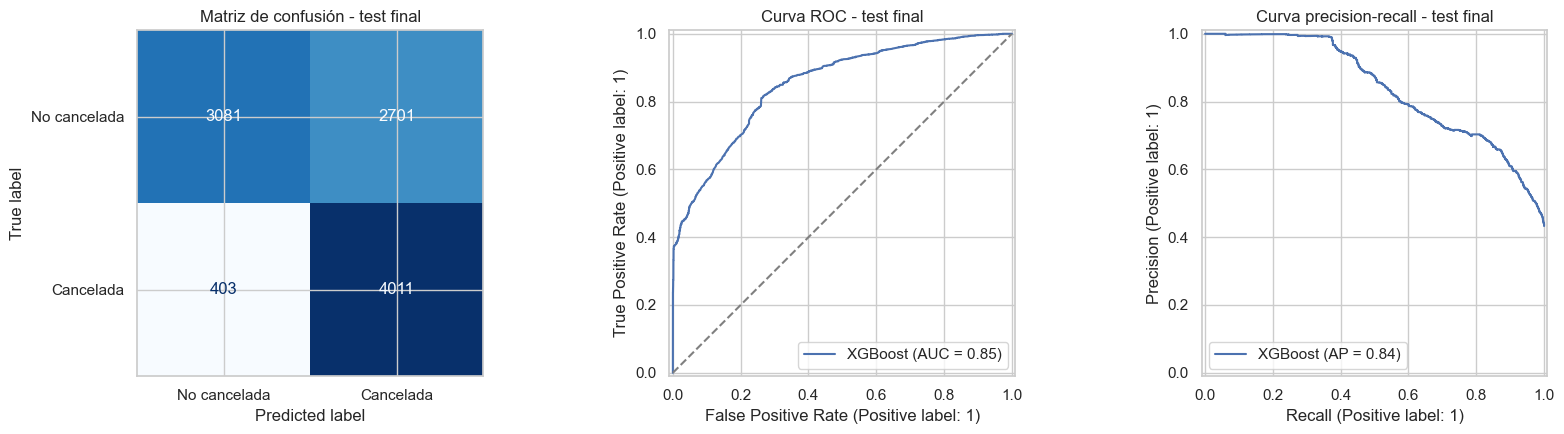

,error_type,reservas,probabilidad_media,lead_time_mediana,porcentaje_test
0,Correcta,7092,0.4159,70.0,69.5567
1,Falso negativo,403,0.1476,22.0,3.9525
2,Falso positivo,2701,0.3952,101.0,26.4908


,grupo,reservas,cancelacion_pct,tn,fp,fn,tp,precision,recall,f1,roc_auc,pr_auc
0,City Hotel,7248,51.1451,1466,2075,211,3496,0.6275,0.9431,0.7536,0.8441,0.8696
1,Resort Hotel,2948,23.9824,1615,626,192,515,0.4514,0.7284,0.5574,0.8119,0.6233


,grupo,reservas,cancelacion_pct,tn,fp,fn,tp,precision,recall,f1,roc_auc,pr_auc
0,0-7,1510,8.7417,1364,14,126,6,0.3000,0.0455,0.0789,0.6647,0.1770
1,8-30,1552,29.8325,593,496,93,370,0.4273,0.7991,0.5568,0.7330,0.5410
2,31-90,2313,50.0649,411,744,100,1058,0.5871,0.9136,0.7149,0.7743,0.7966
3,91-180,3062,55.5846,476,884,63,1639,0.6496,0.9630,0.7759,0.8810,0.9154
4,181-365,1759,54.5196,237,563,21,938,0.6249,0.9781,0.7626,0.8452,0.8786


,grupo,reservas,cancelacion_pct,tn,fp,fn,tp,precision,recall,f1,roc_auc,pr_auc
0,2016-11,5183,42.6394,1617,1356,192,2018,0.5981,0.9131,0.7228,0.8604,0.8434
1,2016-12,5013,43.9657,1464,1345,211,1993,0.5971,0.9043,0.7192,0.8424,0.8357


Evaluación final única completada: TN=3,081, FP=2,701, FN=403, TP=4,011; bloques bootstrap=61, réplicas válidas=2,000.


In [43]:
# EVALUACIÓN FINAL ÚNICA: no reejecutar para tomar decisiones de modelado.
frozen_artifact = joblib.load(MODEL_ARTIFACT_PATH)
frozen_pipeline = frozen_artifact["pipeline"]
frozen_threshold = float(frozen_artifact["threshold"])

assert frozen_artifact["config_id"] == "xgb_depth4"
assert frozen_threshold == 0.22
assert frozen_artifact["training_rows"] == 70_389

X_final_test = df.loc[creation_final_test_index, BASE_MODEL_FEATURES]
y_final_test = df.loc[creation_final_test_index, TARGET_COLUMN].astype(int).to_numpy()
test_probability = frozen_pipeline.predict_proba(X_final_test)[:, 1]
test_prediction = (test_probability >= frozen_threshold).astype(int)

assert len(X_final_test) == 10_196
assert set(creation_final_train_index).isdisjoint(creation_final_test_index)

final_confusion_matrix = confusion_matrix(
    y_final_test, test_prediction, labels=[0, 1]
)
tn, fp, fn, tp = final_confusion_matrix.ravel()
final_metric_values = {
    "precision": precision_score(y_final_test, test_prediction, zero_division=0),
    "recall": recall_score(y_final_test, test_prediction, zero_division=0),
    "f1": f1_score(y_final_test, test_prediction, zero_division=0),
    "roc_auc": roc_auc_score(y_final_test, test_probability),
    "pr_auc": average_precision_score(y_final_test, test_probability),
}

# Bootstrap por bloques diarios de creación aproximada.
test_creation_days = (
    booking_creation_date_proxy.loc[creation_final_test_index]
    .dt.normalize()
    .to_numpy(dtype="datetime64[ns]")
)
unique_creation_days = np.unique(test_creation_days)
positions_by_day = {
    day: np.flatnonzero(test_creation_days == day)
    for day in unique_creation_days
}
bootstrap_rng = np.random.default_rng(RANDOM_STATE)
bootstrap_rows = []

for bootstrap_iteration in range(2_000):
    sampled_days = bootstrap_rng.choice(
        unique_creation_days,
        size=len(unique_creation_days),
        replace=True,
    )
    sampled_positions = np.concatenate([
        positions_by_day[day] for day in sampled_days
    ])
    y_bootstrap = y_final_test[sampled_positions]
    probability_bootstrap = test_probability[sampled_positions]
    prediction_bootstrap = test_prediction[sampled_positions]

    if np.unique(y_bootstrap).size < 2:
        continue
    bootstrap_rows.append({
        "precision": precision_score(y_bootstrap, prediction_bootstrap, zero_division=0),
        "recall": recall_score(y_bootstrap, prediction_bootstrap, zero_division=0),
        "f1": f1_score(y_bootstrap, prediction_bootstrap, zero_division=0),
        "roc_auc": roc_auc_score(y_bootstrap, probability_bootstrap),
        "pr_auc": average_precision_score(y_bootstrap, probability_bootstrap),
    })

bootstrap_metrics = pd.DataFrame(bootstrap_rows)
final_metrics_with_ci = pd.DataFrame([
    {
        "metrica": metric,
        "estimacion": estimate,
        "ic95_inferior": bootstrap_metrics[metric].quantile(0.025),
        "ic95_superior": bootstrap_metrics[metric].quantile(0.975),
    }
    for metric, estimate in final_metric_values.items()
])

display(pd.DataFrame(
    final_confusion_matrix,
    index=["Real no cancelada", "Real cancelada"],
    columns=["Predicha no cancelada", "Predicha cancelada"],
))
display(final_metrics_with_ci.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=final_confusion_matrix,
    display_labels=["No cancelada", "Cancelada"],
).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Matriz de confusión - test final")
RocCurveDisplay.from_predictions(
    y_final_test, test_probability, ax=axes[1], name="XGBoost"
)
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("Curva ROC - test final")
PrecisionRecallDisplay.from_predictions(
    y_final_test, test_probability, ax=axes[2], name="XGBoost"
)
axes[2].set_title("Curva precision-recall - test final")
plt.tight_layout()
plt.show()


def binary_metrics_frame(y_true, prediction, probability, label):
    matrix = confusion_matrix(y_true, prediction, labels=[0, 1])
    local_tn, local_fp, local_fn, local_tp = matrix.ravel()
    return {
        "grupo": label,
        "reservas": len(y_true),
        "cancelacion_pct": 100 * np.mean(y_true),
        "tn": local_tn,
        "fp": local_fp,
        "fn": local_fn,
        "tp": local_tp,
        "precision": precision_score(y_true, prediction, zero_division=0),
        "recall": recall_score(y_true, prediction, zero_division=0),
        "f1": f1_score(y_true, prediction, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probability),
        "pr_auc": average_precision_score(y_true, probability),
    }


test_analysis = df.loc[creation_final_test_index, ["hotel", "lead_time"]].copy()
test_analysis["creation_month"] = (
    booking_creation_date_proxy.loc[creation_final_test_index]
    .dt.to_period("M")
    .astype(str)
)
test_analysis["y_true"] = y_final_test
test_analysis["prediction"] = test_prediction
test_analysis["probability"] = test_probability
test_analysis["error_type"] = np.select(
    [
        (test_analysis["y_true"] == 0) & (test_analysis["prediction"] == 1),
        (test_analysis["y_true"] == 1) & (test_analysis["prediction"] == 0),
    ],
    ["Falso positivo", "Falso negativo"],
    default="Correcta",
)

hotel_metric_rows = []
for hotel_name, group in test_analysis.groupby("hotel"):
    hotel_metric_rows.append(binary_metrics_frame(
        group["y_true"].to_numpy(),
        group["prediction"].to_numpy(),
        group["probability"].to_numpy(),
        hotel_name,
    ))
hotel_metrics = pd.DataFrame(hotel_metric_rows)

test_analysis["lead_time_band"] = pd.cut(
    test_analysis["lead_time"],
    bins=[-np.inf, 7, 30, 90, 180, 365, np.inf],
    labels=["0-7", "8-30", "31-90", "91-180", "181-365", ">365"],
)
lead_time_metric_rows = []
for band, group in test_analysis.groupby("lead_time_band", observed=True):
    if group["y_true"].nunique() == 2:
        lead_time_metric_rows.append(binary_metrics_frame(
            group["y_true"].to_numpy(),
            group["prediction"].to_numpy(),
            group["probability"].to_numpy(),
            str(band),
        ))
lead_time_metrics = pd.DataFrame(lead_time_metric_rows)

month_metric_rows = []
for month, group in test_analysis.groupby("creation_month"):
    month_metric_rows.append(binary_metrics_frame(
        group["y_true"].to_numpy(),
        group["prediction"].to_numpy(),
        group["probability"].to_numpy(),
        month,
    ))
creation_month_metrics = pd.DataFrame(month_metric_rows)

error_summary = (
    test_analysis.groupby("error_type")
    .agg(
        reservas=("error_type", "size"),
        probabilidad_media=("probability", "mean"),
        lead_time_mediana=("lead_time", "median"),
    )
    .reset_index()
)
error_summary["porcentaje_test"] = 100 * error_summary["reservas"] / len(test_analysis)

display(error_summary.round(4))
display(hotel_metrics.round(4))
display(lead_time_metrics.round(4))
display(creation_month_metrics.round(4))

print(
    f"Evaluación final única completada: TN={tn:,}, FP={fp:,}, "
    f"FN={fn:,}, TP={tp:,}; bloques bootstrap={len(unique_creation_days)}, "
    f"réplicas válidas={len(bootstrap_metrics):,}."
)


## 5.3 Resultados, errores, riesgos y cierre

### Resultado final congelado

Se reentrenó `xgb_depth4` con el pipeline completo sobre las **70.389 reservas elegibles de desarrollo**, conservando las variables originales admitidas, las ocho variables nuevas y el umbral fijo **0,22**. El test de **10.196 reservas** se evaluó una sola vez. No se ajustaron variables, hiperparámetros ni umbral después de observarlo.

La matriz de confusión fue **TN=3.081, FP=2.701, FN=403 y TP=4.011**. Las métricas finales fueron: precision **0,5976**, recall **0,9087**, F1 **0,7210**, ROC-AUC **0,8520** y PR-AUC **0,8398**.

Los intervalos del 95% se estimaron con 2.000 réplicas de bootstrap por bloques de fecha aproximada de creación (61 días): precision **[0,5106; 0,6765]**, recall **[0,8719; 0,9370]**, F1 **[0,6459; 0,7846]**, ROC-AUC **[0,8039; 0,8894]** y PR-AUC **[0,7220; 0,9078]**. El remuestreo por día conserva parte de la dependencia temporal, pero no elimina correlaciones entre días, hoteles o clientes. Además, el test cubre solo dos meses y la fecha de creación es aproximada; por eso los intervalos no representan toda la incertidumbre de despliegue.

### Errores y heterogeneidad

El umbral prioriza sensibilidad: se detectó el **90,87%** de las cancelaciones, a costa de **2.701 falsos positivos** (26,49% del test). Los **403 falsos negativos** representan 3,95% del test. Para el hotel, un falso positivo puede provocar contacto, incentivos o sobreventa innecesarios y deteriorar la experiencia; un falso negativo deja una cancelación sin anticipar y puede afectar inventario, personal e ingresos.

El rendimiento fue mejor en **City Hotel** (F1 0,7536; recall 0,9431; PR-AUC 0,8696) que en **Resort Hotel** (F1 0,5574; recall 0,7284; PR-AUC 0,6233). La principal debilidad aparece en reservas con `lead_time` de 0 a 7 días: recall 0,0455 y F1 0,0789, con solo 132 cancelaciones; desde 31 días el recall supera 0,91. Entre noviembre y diciembre el F1 fue similar (0,7228 frente a 0,7192), aunque ROC-AUC bajó de 0,8604 a 0,8424. Estos cortes son descriptivos y no se usaron para reajustar el modelo.

### Limitaciones y monitoreo

- La fecha de creación se aproxima como llegada menos `lead_time`; no es una marca temporal observada.
- Algunas variables podrían haber sido actualizadas después de registrar la reserva. Se excluyeron las claramente posteriores o inciertas según la auditoría, pero el dataset no permite garantizar el instante de cada actualización.
- Hubo exposición histórica de **2.923** filas del test durante un EDA anterior. No se usaron para entrenar ni ajustar la Etapa 4 o 5, pero no puede afirmarse aislamiento ciego desde el inicio.
- Existen cambios de distribución entre hoteles, niveles de anticipación y períodos; el test de noviembre-diciembre de 2016 no garantiza desempeño futuro ni en otros establecimientos.
- Las importancias y SHAP son asociaciones dependientes de la muestra, la codificación y las correlaciones; no prueban causalidad.

En producción deberían monitorearse faltantes y categorías nuevas, deriva de variables y probabilidades, tasa de alertas, calibración y, cuando maduren las etiquetas, precision, recall y F1 globales y por hotel, período y bandas de `lead_time`. Correspondería reentrenar ante una caída sostenida del desempeño, deriva relevante, cambios comerciales o del sistema de reservas, y también mediante una revisión periódica definida por el volumen de nuevas etiquetas. Todo reentrenamiento debe repetir la validación temporal y usar un test futuro nuevo; el test actual no debe reutilizarse para selección.
